# Subset Selection and Shrinkage Methods for Regression

In Practical 4 the complexity of a model was controlled by one knob, such as the number of neighbours $k$ in k-NN or
the depth of a decision tree, and we chose the knob by cross-validation. This practical 5 goes back to the very first
model of Practical 1, **linear regression**, and asks the same question: *how complex should it be?*

A linear regression model predicts

$$\hat y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p .$$

Its complexity has two sides:

1. **how many** predictors it uses, that is, how many of the $\beta_j$ are allowed to be non-zero, and
2. **how large** the coefficients $\beta_j$ are allowed to become.

**Ordinary least squares (OLS)**, the method of Practical 1, uses every predictor and lets the coefficients be as large
as they like. That works well when the predictors are unrelated to each other. It goes wrong when some predictors are
**strongly correlated**: OLS cannot tell which of two near copies deserves the credit, so it may give one of them a
large positive coefficient and the other a large negative one. The predictions are often still fine, but the
coefficients become unstable and meaningless, and with many predictors the model starts to overfit.

There are two families of fixes, and this practical builds both of them from scratch:

- **Subset selection** keeps only *some* of the predictors and fits OLS on those. We build **best-subset** selection
  and **forward** and **backward stepwise** selection, and compare models of different sizes with **AIC**, **BIC**,
  **Mallows' $C_p$** and **adjusted $R^2$**.
- **Shrinkage** (also called **regularisation**) keeps *all* the predictors but adds a penalty that pulls the
  coefficients towards zero. We build **ridge regression** (closed form) and the **lasso** (coordinate descent), draw
  their **shrinkage paths**, and choose the strength of the penalty by **cross-validation**.

The practical has eight parts:

0. **The Diabetes dataset**, a standard public benchmark built into scikit-learn.
1. **Lock away the test set**, standardise the features, and look at which predictors are correlated.
2. **OLS from scratch**, what correlated predictors do to it, why the training fit cannot choose the number of
   predictors, and the **four model-selection criteria**, checked against `statsmodels`.
3. **Best-subset selection**: every possible set of predictors.
4. **Forward and backward stepwise selection**, checked against `SequentialFeatureSelector`.
5. **Ridge regression** in closed form and the **lasso** by coordinate descent, checked against `Ridge` and `Lasso`.
6. **Shrinkage paths**, and choosing the penalty $\lambda$ by cross-validation, checked against `GridSearchCV`.
7. **OLS, subset selection, ridge and lasso compared** on the untouched test set: test error, stability of the
   coefficients, and the number of coefficients driven to zero. First on the 10 original features, then on 55
   strongly correlated features.

**What is new in the toolbox.** As in Practical 4, every method is written **from scratch** in NumPy and then checked
against a library. The library is mostly scikit-learn again; one check (AIC and BIC) uses **statsmodels**, a second
standard Python library for statistics.

**Vocabulary used throughout**

| term | meaning in this notebook |
|-|-|
| **predictor** | another word for a feature: one column of $X$ |
| **correlated predictors** | two or more predictors that carry nearly the same information (also called *multicollinearity*) |
| **RSS** | residual sum of squares $\sum_i (y_i - \hat y_i)^2$: how closely a model fits its training rows (smaller is closer) |
| **subset selection** | choosing which predictors to keep, then fitting OLS on them |
| **model-selection criterion** | a score made of *training fit plus a penalty for size* (AIC, BIC, $C_p$, adjusted $R^2$) |
| **shrinkage / regularisation** | pulling coefficients towards zero by adding a penalty on their size |
| **ridge** | shrinkage with the penalty $\lambda \sum_j \beta_j^2$ |
| **lasso** | shrinkage with the penalty $\lambda \sum_j \lvert\beta_j\rvert$ |
| **regularisation parameter $\lambda$** | a hyper-parameter: the strength of the penalty. $\lambda = 0$ gives OLS; a huge $\lambda$ pushes every coefficient to 0 |
| **shrinkage path** | every coefficient plotted against $\lambda$ |
| **sparse** | a coefficient vector with many coefficients exactly equal to 0 |
| **standardise** | rescale a column to mean 0 and standard deviation 1 |
| **development set** | all rows except the test set (Practical 4) |

**Notation**

| symbol | meaning |
|-|-|
| $n$, $p$ | number of rows and number of predictors ($p = 10$ for Diabetes) |
| $d$ | number of predictors used by one particular model, $0 \le d \le p$ |
| $\beta_0$, $\beta = (\beta_1, \dots, \beta_p)$ | the intercept and the coefficients |
| $\text{RSS} = \sum_i (y_i - \beta_0 - x_i^{\top}\beta)^2$ | residual sum of squares on the training rows |
| $\text{TSS} = \sum_i (y_i - \bar y)^2$ | total sum of squares: the RSS of the model that always predicts the mean $\bar y$ |
| $R^2 = 1 - \text{RSS}/\text{TSS}$ | fraction of the variance of $y$ explained by the model |
| $\hat\sigma^2$ | estimated variance of the noise in $y$ |
| $\lambda$ | regularisation parameter (scikit-learn calls it `alpha`) |

(In Practical 4 we wrote $d$ for the number of columns of $X$. Here we need two numbers, so $p$ is the number of
columns and $d$ the number a particular model uses.)

In [1]:
import numpy as np                      # arrays and all the numerical work
import pandas as pd                     # tables, so results print with readable labels
import matplotlib.pyplot as plt         # every plot in this notebook
import itertools                        # combinations(): every subset of a given size

from sklearn.datasets import load_diabetes                             # the standard public dataset
from sklearn.preprocessing import StandardScaler, PolynomialFeatures   # rescaling, and products of features
from sklearn.pipeline import make_pipeline                             # chain "standardise, then model" into one object
from sklearn.model_selection import train_test_split, KFold            # hold-out split and K-fold (Practical 4)

# Library versions of everything we build from scratch. They are used ONLY to check our own code.
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import GridSearchCV
import statsmodels.api as sm            # a second statistics library, used only to check AIC, BIC and adjusted R^2

%matplotlib inline

rng = np.random.default_rng(42)                    # one seeded generator for general random numbers
np.set_printoptions(precision=4, suppress=True)    # 4 decimals, no scientific notation
pd.set_option("display.precision", 4)              # same idea for DataFrames
pd.set_option("display.width", 150)                # wide tables print on one line
plt.rcParams["figure.figsize"] = (6, 4)            # default plot size in inches
plt.rcParams["figure.dpi"] = 150                   # default resolution

**Line by line**

- The first three imports are the same as in every practical so far. `itertools` is part of standard Python; its
  function `combinations` lists every subset of a given size, which is exactly what best-subset selection needs.
- `StandardScaler` rescales columns to mean 0 and standard deviation 1. `PolynomialFeatures` builds new columns from
  products of the old ones; we use it in Part 7.
- `train_test_split` and `KFold` were written from scratch and checked in Practical 4, where our own functions gave
  exactly the same rows. Here we simply use the library versions.
- The block under the comment brings in the library versions of everything we build. Read the comment: we never use
  them to *do* the work, only to **check** the functions we write ourselves.
- `import statsmodels.api as sm` : **statsmodels** is a standard Python library for classical statistics. If this line
  fails, install it once with `uv add statsmodels` in a terminal and restart the notebook.
- `rng = np.random.default_rng(42)` : the seeded generator of Practicals 2 to 4. Run the notebook from top to bottom
  (*Kernel, Restart & Run All*) to get exactly the numbers quoted in the text.

## Part 0: The Diabetes dataset

We met this dataset in Practical 4. It comes from Efron, Hastie, Johnstone and Tibshirani's 2004 paper *Least Angle
Regression*, the paper that made it the standard small benchmark for the lasso. Each row is one diabetes patient. The
target is a number measuring **how far the disease has progressed one year** after the measurements were taken. The
ten features are:

| column | meaning |
|-|-|
| `age` | age in years |
| `sex` | sex (two values) |
| `bmi` | body-mass index |
| `bp` | average blood pressure |
| `s1` | total serum cholesterol |
| `s2` | LDL cholesterol ("bad" cholesterol) |
| `s3` | HDL cholesterol ("good" cholesterol) |
| `s4` | total cholesterol divided by HDL |
| `s5` | log of the serum triglycerides level |
| `s6` | blood sugar level |

Six of the features (`s1` to `s6`) are blood measurements, and several of them measure overlapping things. Total
cholesterol, for example, is largely made up of LDL cholesterol. That makes this dataset a natural place to see what
correlated predictors do to least squares.

In [2]:
diabetes = load_diabetes()                          # a "Bunch": a dictionary-like object holding the dataset
X = diabetes.data                                   # (442, 10) feature matrix, one patient per row
y = diabetes.target                                 # (442,) disease progression after one year
feature_names = np.array(diabetes.feature_names)    # the 10 column names, as an array so we can index it

print("feature matrix X :", X.shape)
print("target vector y  :", y.shape)
print("features         :", feature_names.tolist())
print(f"target           : from {y.min():.0f} to {y.max():.0f}, mean {y.mean():.1f}, variance {y.var():.1f}")

print("\nthe columns arrive already rescaled by scikit-learn:")
print("  every column has mean 0         :", np.allclose(X.mean(axis=0), 0))
print("  every column has sum of squares 1:", np.allclose((X ** 2).sum(axis=0), 1))
print("  the two values of 'sex'          :", np.unique(X[:, 1]))

pd.DataFrame(X, columns=feature_names).assign(progression=y).head()

feature matrix X : (442, 10)
target vector y  : (442,)
features         : ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
target           : from 25 to 346, mean 152.1, variance 5929.9

the columns arrive already rescaled by scikit-learn:
  every column has mean 0         : True
  every column has sum of squares 1: True
  the two values of 'sex'          : [-0.0446  0.0507]


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0


**Line by line**

- `load_diabetes()` returns a **Bunch**, as in Practical 4: `diabetes.data` is the feature matrix and
  `diabetes.target` the target vector.
- `np.array(diabetes.feature_names)` : the names arrive as a plain Python list. Turning them into a NumPy array lets
  us pick several names at once with a list of positions, for example `feature_names[[4, 5]]` gives
  `['s1', 's2']`. We will use this all the time to print which features a model uses.
- `y.var()` : the variance of the target. A model that ignores the features and always predicts the average has a
  mean squared error equal to this number, so it is the **baseline** every model must beat (Practical 4).
- `np.allclose(X.mean(axis=0), 0)` : `axis=0` means "down the rows", so we get one mean per column.
- `.assign(progression=y)` : adds the target as an extra column of the table, only for display. `.head()` shows the
  first five rows.

**Reading the output.** There are 442 patients and 10 features. The target runs from 25 to 346 with a variance of
about 5930, so a useless model has a mean squared error of about 5930.

Notice that scikit-learn has **already rescaled** the columns: each has mean 0, and the squares of each column add
up to 1. That is why the numbers in the table are small and why `sex` takes the strange values $-0.0446$ and
$0.0507$. This rescaling was done on **all 442 rows together**, but it does not matter for us: it is just a change
of units, and in Part 1 we standardise the columns properly ourselves, using the development rows only.

## Part 1: Lock away the test set, standardise, and look at the correlations

### 1a. The test set comes first

The golden rule of Practical 4 still holds: **before any plotting, modelling or choosing, cut off the test set and lock
it away.** We put 20% of the rows aside and use the same seed as in Practical 4.

We keep the **raw** (not yet standardised) versions of both parts, `X_dev_raw` and `X_test_raw`, because two later
steps need them: cross-validation in Part 6 must standardise inside every fold, and Part 7 builds new features from the
raw values.

In [3]:
SEED_TEST = 2026                                   # fixed once, never changed afterwards
X_dev_raw, X_test_raw, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED_TEST)
n_dev, p = X_dev_raw.shape                         # number of development rows, number of predictors

print(f"development set : {n_dev} patients")
print(f"test set        : {len(y_test)} patients   (locked away until Part 7)")
print(f"number of predictors p = {p}")
print(f"mean progression: development {y_dev.mean():.1f},  test {y_test.mean():.1f}")

development set : 353 patients
test set        : 89 patients   (locked away until Part 7)
number of predictors p = 10
mean progression: development 152.7,  test 149.8


**Line by line**

- `train_test_split(X, y, test_size=0.2, random_state=SEED_TEST)` : the hold-out split of Practical 4. It returns four
  arrays in the order train-X, test-X, train-y, test-y. In Practical 4 our own `holdout_split` gave exactly the same
  rows, so this is the method we already understand.
- `n_dev, p = X_dev_raw.shape` : `.shape` is a pair (rows, columns), and Python lets us unpack it into two names at
  once.

**Reading the output.** 353 development patients and 89 test patients. **From here until Part 7, `X_test_raw` and
`y_test` are not used.** Every choice in Parts 1 to 6 (which predictors, which criterion, which $\lambda$) is made
with the 353 development rows only.

### 1b. Standardising the features

Ridge and the lasso punish the **size** of the coefficients. But the size of a coefficient depends on the **units**
of its feature: if blood pressure were measured in kilopascals instead of mmHg, its coefficient would be about 7.5
times larger, and the penalty would treat it differently, although nothing real has changed. To make the penalty
fair, every feature is first put on the same scale:

$$z_{ij} = \frac{x_{ij} - \text{mean}_j}{\text{sd}_j},$$

so every column has mean 0 and standard deviation 1. After this, every coefficient means the same kind of thing:
*the change in predicted progression when this feature goes up by one standard deviation.*

The mean and standard deviation are computed from the **development rows only**, and the same two numbers are then
used on the test rows. Computing them from all rows would let a little information from the test set leak into
training (Practical 4, Exercise 4). We call the standardised matrices `Z` to keep them apart from the raw `X`.

In [4]:
def standardise(X_fit, X_apply):
    '''Rescale the columns of X_apply using the mean and standard deviation of the columns of X_fit.'''
    mean = X_fit.mean(axis=0)                      # one mean per column, from X_fit only
    sd = X_fit.std(axis=0)                         # one standard deviation per column, from X_fit only
    return (X_apply - mean) / sd


Z_dev = standardise(X_dev_raw, X_dev_raw)          # development rows, scaled with their own statistics
Z_test = standardise(X_dev_raw, X_test_raw)        # test rows, scaled with the DEVELOPMENT statistics

# the library check
scaler = StandardScaler().fit(X_dev_raw)
print("same as StandardScaler on the development rows:", np.allclose(Z_dev, scaler.transform(X_dev_raw)))
print("same as StandardScaler on the test rows       :", np.allclose(Z_test, scaler.transform(X_test_raw)))

print("\ndevelopment column means   :", Z_dev.mean(axis=0).round(3) + 0.0)
print("development column std devs:", Z_dev.std(axis=0).round(3))
print("test column means          :", Z_test.mean(axis=0).round(3))

same as StandardScaler on the development rows: True
same as StandardScaler on the test rows       : True

development column means   : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
development column std devs: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
test column means          : [-0.068  0.236  0.025 -0.105  0.112  0.054 -0.023  0.029  0.109 -0.031]


**Line by line**

- `X_fit.mean(axis=0)` and `X_fit.std(axis=0)` : ten means and ten standard deviations, one per column.
- `(X_apply - mean) / sd` : NumPy **broadcasting** (Practical 1). `X_apply` has shape `(rows, 10)` and `mean` has
  shape `(10,)`, so the ten means are subtracted from every row, column by column.
- `standardise(X_dev_raw, X_test_raw)` : the test rows are scaled with the **development** mean and standard
  deviation. This is exactly what a scaler fitted on the training data does to new data.
- `StandardScaler().fit(X_dev_raw)` learns the same two vectors, and `.transform(...)` applies them. Both checks
  print `True`.
- `.round(3) + 0.0` : rounding a tiny negative number such as $-0.0000001$ gives $-0.0$. Adding $0.0$ turns these
  "negative zeros" into ordinary zeros, purely so the printout looks clean.

**Reading the output.** On the development rows every column now has mean exactly 0 and standard deviation exactly 1.
On the test rows the means are close to 0 but not equal to it, because the test patients are a different random
sample. That is how it should be: the test set is treated like new patients arriving later.

### 1c. Which predictors are correlated?

The **correlation** between two features is a number between $-1$ and $+1$ (Practical 2). Near $+1$ means that when
one is high the other is high too; near $-1$ means that when one is high the other is low; near 0 means no linear
relationship. We compute it for every pair of features, on the development rows only.

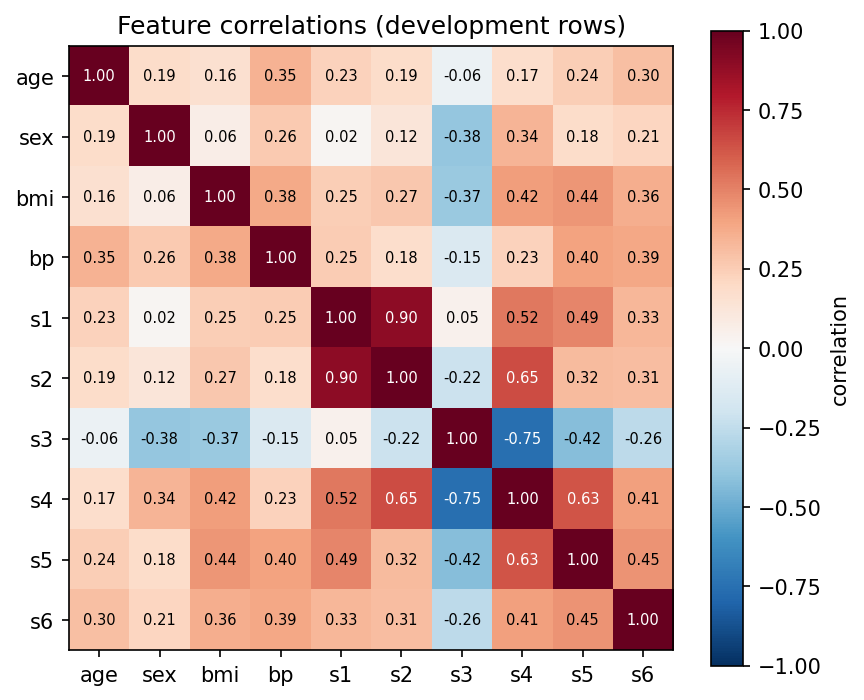

45 pairs of features; the six most strongly correlated:


,feature 1,feature 2,correlation,strength
30,s1,s2,0.8978,0.8978
39,s3,s4,-0.7527,0.7527
36,s2,s4,0.6531,0.6531
42,s4,s5,0.6316,0.6316
32,s1,s4,0.5240,0.5240
33,s1,s5,0.4889,0.4889


In [5]:
corr = np.corrcoef(Z_dev, rowvar=False)            # (10, 10) correlation matrix of the development features

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)        # red = positive, blue = negative
for i in range(p):
    for j in range(p):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr[i, j]) > 0.6 else "black")       # white text on dark squares
ax.set_xticks(range(p))
ax.set_xticklabels(feature_names)
ax.set_yticks(range(p))
ax.set_yticklabels(feature_names)
fig.colorbar(image, ax=ax, label="correlation")
ax.set_title("Feature correlations (development rows)")
plt.show()

pairs = pd.DataFrame([(feature_names[i], feature_names[j], corr[i, j])
                      for i in range(p) for j in range(i + 1, p)],
                     columns=["feature 1", "feature 2", "correlation"])
pairs["strength"] = pairs["correlation"].abs()
print(f"{len(pairs)} pairs of features; the six most strongly correlated:")
pairs.sort_values("strength", ascending=False).head(6)

**Line by line**

- `np.corrcoef(Z_dev, rowvar=False)` : by default `corrcoef` treats every *row* as a variable. `rowvar=False` tells it
  that our variables are the *columns*, so we get a $10 \times 10$ matrix whose entry $(i, j)$ is the correlation
  between feature $i$ and feature $j$. The diagonal is always 1.
- `ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)` : draws the matrix as coloured squares. `RdBu_r` is a red and blue
  colour map, and fixing `vmin` and `vmax` at $-1$ and $1$ makes white mean exactly 0.
- The double loop writes each correlation, rounded to two decimals, in the middle of its square. Note the order
  `ax.text(j, i, ...)`: the horizontal position is the column $j$, the vertical position is the row $i$. The text is
  white on the dark squares (strong correlations) so that it stays readable.
- The list comprehension visits every pair $(i, j)$ with $j > i$ once: the matrix is symmetric, so the other half
  holds the same numbers. With 10 features there are $10 \times 9 / 2 = 45$ pairs.
- `pairs["strength"] = pairs["correlation"].abs()` : a strong negative correlation is as important as a strong
  positive one, so we sort by the absolute value.

**Reading the plot and the table.**

- The strongest pair by far is **`s1` and `s2`, with a correlation of 0.90**. Total cholesterol (`s1`) is largely
  made up of LDL cholesterol (`s2`), so the two numbers rise and fall together.
- **`s3` and `s4` have a correlation of $-0.75$**. `s4` is total cholesterol *divided by* HDL (`s3`), so a high HDL
  gives a low ratio.
- `s4` is also fairly strongly related to `s2` (0.65) and to `s5` (0.63).
- The non-blood features (`age`, `sex`, `bmi`, `bp`) are only mildly correlated with anything.

So the six blood measurements form a tangled group. Part 2 shows what this does to least squares.

## Part 2: Least squares, and four ways to judge a model's size

### 2a. OLS from scratch, checked against `LinearRegression`

Ordinary least squares chooses $\beta_0$ and $\beta$ to make the RSS as small as possible. In Practical 1 we found the
answer with the **normal equations**: put a column of ones in front of the feature matrix (for the intercept), call
the result $A$, and solve

$$A^{\top}A \, w = A^{\top}y, \qquad w = (\beta_0, \beta_1, \dots, \beta_p).$$

In [6]:
def ols_fit(Z, y):
    '''Ordinary least squares with an intercept, by the normal equations.

    Z       : (n, d) feature matrix (d may be 0: then the model is just the intercept)
    y       : (n,) target vector
    returns : (b0, b), the intercept and the d coefficients
    '''
    A = np.column_stack([np.ones(len(y)), Z])          # a column of 1s in front, for the intercept
    w = np.linalg.solve(A.T @ A, A.T @ y)              # solve the normal equations  (A^T A) w = A^T y
    return w[0], w[1:]


def predict(b0, b, Z):
    '''Predictions of a linear model: b0 + Z b.'''
    return b0 + Z @ b


def mse(y_true, y_pred):
    '''Mean squared error, as in Practical 4.'''
    return np.mean((y_true - y_pred) ** 2)


b0_ols, b_ols = ols_fit(Z_dev, y_dev)

# the library check
lib = LinearRegression().fit(Z_dev, y_dev)
print("same coefficients as LinearRegression:", np.allclose(b_ols, lib.coef_))
print("same intercept as LinearRegression   :", np.isclose(b0_ols, lib.intercept_))

print(f"\nintercept = {b0_ols:.2f}   (the mean of y_dev is {y_dev.mean():.2f})")
print(f"training MSE = {mse(y_dev, predict(b0_ols, b_ols, Z_dev)):.1f}")
pd.Series(b_ols, index=feature_names, name="OLS coefficient").to_frame().T

same coefficients as LinearRegression: True
same intercept as LinearRegression   : True

intercept = 152.73   (the mean of y_dev is 152.73)
training MSE = 2901.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
OLS coefficient,-0.2628,-12.0293,24.1495,16.5122,-40.4625,23.2797,4.7473,8.7128,35.6484,2.7397


**Line by line**

- `np.column_stack([np.ones(len(y)), Z])` : glues a column of ones to the left of `Z`. Its coefficient becomes the
  intercept. If `Z` has no columns at all, `A` is just the column of ones, and the model predicts a constant.
- `np.linalg.solve(M, v)` : solves the linear system $M w = v$. This is faster and more accurate than computing the
  inverse $M^{-1}$ and multiplying, although the result is mathematically the same.
- `w[0], w[1:]` : the first entry is the intercept, the rest are the coefficients.
- `predict` and `mse` are tiny helper functions that we will use in every part.
- `LinearRegression().fit(Z_dev, y_dev)` : the library's least squares. It stores the intercept in `.intercept_` and
  the coefficients in `.coef_`.
- `pd.Series(...).to_frame().T` : shows the ten coefficients as one labelled row.

**Reading the output.**

- Both checks print `True`: our three-line function is exactly `LinearRegression`.
- The intercept is exactly the mean of `y_dev`. This always happens when every column of `Z` has mean 0: at the
  "average patient" (all $z_j = 0$) the model predicts the average progression.
- Because the features are standardised, the coefficients can be compared directly. The largest are `s1` ($-40.5$),
  `s5` ($35.7$), `bmi` ($24.2$) and `s2` ($23.3$).

Now look at `s1` and `s2` together. Total cholesterol gets a **large negative** coefficient and LDL cholesterol, which
is most of total cholesterol, gets a **large positive** one. Does a patient with higher total cholesterol really
progress *more slowly*? The next section shows that this is not a medical finding, but a symptom of correlated
predictors.

### 2b. What correlated predictors do to least squares

We fit OLS four times: with `s1` alone, with `s2` alone, with both, and with all ten features, and watch the
coefficients of `s1` and `s2`.

In [7]:
rows = []
for cols in [[4], [5], [4, 5], list(range(p))]:               # column 4 is s1, column 5 is s2
    b0, b = ols_fit(Z_dev[:, cols], y_dev)
    coef = dict(zip(feature_names[cols], b))                   # feature name -> its coefficient in this model
    rows.append({"features in the model": "all ten" if len(cols) == p else ", ".join(feature_names[cols]),
                 "s1 coefficient": coef.get("s1", np.nan),
                 "s2 coefficient": coef.get("s2", np.nan)})
pd.DataFrame(rows)

,features in the model,s1 coefficient,s2 coefficient
0,s1,13.4407,NaN
1,s2,NaN,11.6435
2,"s1, s2",15.4028,-2.1854
3,all ten,-40.4625,23.2797


**Line by line**

- `Z_dev[:, cols]` : all rows, only the listed columns. The model is fitted on just those features.
- `dict(zip(names, values))` : pairs each feature name with its coefficient, so we can look a coefficient up by name.
- `coef.get("s1", np.nan)` : the coefficient of `s1` if it is in the model, otherwise `NaN` ("not a number"), which
  pandas shows as an empty value.
- `", ".join(...)` : glues the names into one string such as `"s1, s2"`.

**Reading the output.**

- **On its own**, each of the two features gets a **positive** coefficient (about 13.4 and 11.6): higher cholesterol
  goes with faster progression. That is the honest one-feature answer.
- **Together**, the credit is split very unevenly: `s1` gets 15.4 and `s2` gets $-2.2$.
- **With all ten features**, which bring in the other cholesterol measurements `s3` and `s4`, the coefficients
  explode to $-40.5$ and $+23.3$, with opposite signs.

Why? Because `s1` and `s2` almost always move together, the data contain very little information about what happens
when one goes up **and the other does not**. To split the credit between them, OLS has to answer exactly that
question, and it answers it from the few patients whose `s1` and `s2` disagree. That answer is mostly noise. For a
typical patient, where the two move together, a big negative and a big positive coefficient nearly cancel, so the
predictions are hardly affected, which is why OLS is perfectly happy with them. But the coefficients themselves can
no longer be trusted. In Part 7 we will measure this directly: refit on slightly different data, and see how much the
coefficients jump around.

### 2c. More predictors always look better on the training rows

Before we try to choose a subset of predictors, one warning. Let us add columns of **pure random noise** to the
development set, one at a time, and watch the training RSS and $R^2$.

In [8]:
def rss(Z, y, cols):
    '''Residual sum of squares of the OLS model that uses only the columns listed in cols.'''
    b0, b = ols_fit(Z[:, cols], y)
    residuals = y - predict(b0, b, Z[:, cols])
    return residuals @ residuals                     # the sum of the squared residuals


tss = np.sum((y_dev - y_dev.mean()) ** 2)            # RSS of the model that always predicts the mean

Z_noise = Z_dev.copy()
rows = []
for k in range(6):
    if k > 0:
        Z_noise = np.column_stack([Z_noise, rng.normal(size=n_dev)])   # one more column of pure noise
    r = rss(Z_noise, y_dev, list(range(Z_noise.shape[1])))           # OLS on ALL columns so far
    rows.append({"noise columns added": k, "predictors": Z_noise.shape[1],
                 "RSS": int(round(r)), "R^2": 1 - r / tss})
pd.DataFrame(rows).set_index("noise columns added")

,predictors,RSS,R^2
noise columns added,,,
0,10,1024051,0.5105
1,11,1020343,0.5123
2,12,1019879,0.5125
3,13,1019540,0.5127
4,14,1019307,0.5128
5,15,1018120,0.5133


**Line by line**

- `rss(Z, y, cols)` : fits OLS on the chosen columns and returns its RSS. This small function is the building block
  of all the subset-selection methods below.
- `residuals @ residuals` : the dot product of a vector with itself is the sum of its squared entries.
- `tss` : the total sum of squares, the RSS of the model with no predictors at all.
- `rng.normal(size=n_dev)` : 353 random numbers from a standard normal distribution. They have **nothing** to do with
  diabetes.
- `Z_dev.copy()` : a separate copy, so that adding columns to `Z_noise` leaves `Z_dev` untouched.
- `int(round(r))` : the RSS is a number around one million; showing it as a whole number keeps the table readable.

**Reading the output.** Every column of noise **lowers** the RSS and **raises** $R^2$ (from 0.5105 to 0.5133 after
five columns), although the new columns are pure noise.

This is not a coincidence, it is guaranteed. A model with one extra column could always set that column's coefficient
to 0 and get the old fit back, so its best fit can only be the same or better. Therefore **the training RSS (or $R^2$)
can never choose how many predictors to use**: it always says "use all of them, and more if you have them". This is
the same lesson as in Practical 4: training error cannot be trusted for choosing. We need a fairer score.

### 2d. Four model-selection criteria

The four classical answers all have the same shape: **training fit plus a penalty for every parameter**. For an OLS
model with $d$ predictors plus an intercept (so $d + 1$ fitted parameters), fitted on $n$ rows:

$$\text{AIC} = n\ln\!\left(\frac{\text{RSS}}{n}\right) + 2(d+1), \qquad
\text{BIC} = n\ln\!\left(\frac{\text{RSS}}{n}\right) + (d+1)\ln n,$$

$$C_p = \frac{\text{RSS}}{\hat\sigma^2} - n + 2(d+1), \qquad
R^2_{\text{adj}} = 1 - \frac{\text{RSS}/(n-d-1)}{\text{TSS}/(n-1)} .$$

- **AIC** (Akaike information criterion). The first term falls as the fit improves; the second adds 2 for every
  parameter. **Lower is better.**
- **BIC** (Bayesian information criterion). The same, but every parameter costs $\ln n$ instead of 2. With
  $n = 353$, $\ln n \approx 5.87$, so each extra predictor costs about three times as much as in AIC. BIC therefore
  tends to choose **smaller** models. **Lower is better.**
- **Mallows' $C_p$**. Here $\hat\sigma^2 = \text{RSS}_{\text{full}} / (n - p - 1)$ is the noise variance estimated
  from the full model with all $p$ predictors. A good model has $C_p$ close to its number of parameters $d + 1$.
  **Lower is better.**
- **Adjusted $R^2$**. Ordinary $R^2 = 1 - \text{RSS}/\text{TSS}$ always rises with more predictors (2c). The adjusted
  version divides RSS by $n - d - 1$, so a useless extra predictor, which lowers RSS only a tiny bit but lowers
  $n - d - 1$ by one, can make it go *down*. **Higher is better.**

AIC and $C_p$ are both estimates of the **test error**; for linear regression they almost always choose the same
model. BIC comes from a different (Bayesian) argument and prefers the simplest model that explains the data well.

Notice what these criteria do **not** need: a validation set. They are computed from the training rows alone and
replace the hold-out by a penalty. That is their attraction, and also their weakness: the penalty is only correct
under assumptions about the model (for example, that the noise is normal with constant variance).

In [9]:
rss_full = rss(Z_dev, y_dev, list(range(p)))        # RSS of the full model with all p predictors
sigma2_hat = rss_full / (n_dev - p - 1)             # estimated noise variance, used by Cp


def criteria(rss_value, d, n=n_dev, tss=tss, sigma2=sigma2_hat):
    '''The four model-selection scores of an OLS model with d predictors plus an intercept.'''
    k = d + 1                                        # number of fitted parameters, intercept included
    return {"AIC": n * np.log(rss_value / n) + 2 * k,
            "BIC": n * np.log(rss_value / n) + np.log(n) * k,
            "Cp": rss_value / sigma2 - n + 2 * k,
            "adj R^2": 1 - (rss_value / (n - d - 1)) / (tss / (n - 1))}


print(f"estimated noise standard deviation sigma_hat = {np.sqrt(sigma2_hat):.2f}\n")

# the library check, on the full model and on a small model (bmi, bp, s5)
shift = n_dev * (1 + np.log(2 * np.pi))             # the constant that statsmodels keeps and we drop
for cols in [list(range(p)), [2, 3, 8]]:
    ours = criteria(rss(Z_dev, y_dev, cols), len(cols))
    lib = sm.OLS(y_dev, sm.add_constant(Z_dev[:, cols])).fit()
    print("model with", ", ".join(feature_names[cols]))
    print("   our AIC + shift = statsmodels AIC  :", np.isclose(ours["AIC"] + shift, lib.aic))
    print("   our BIC + shift = statsmodels BIC  :", np.isclose(ours["BIC"] + shift, lib.bic))
    print("   our adjusted R^2 = statsmodels     :", np.isclose(ours["adj R^2"], lib.rsquared_adj))

print(f"\nCp of the full model = {criteria(rss_full, p)['Cp']:.4f}   (must be exactly p + 1 = {p + 1})")
criteria(rss_full, p)

estimated noise standard deviation sigma_hat = 54.72

model with age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
   our AIC + shift = statsmodels AIC  : True
   our BIC + shift = statsmodels BIC  : True
   our adjusted R^2 = statsmodels     : True
model with bmi, bp, s5
   our AIC + shift = statsmodels AIC  : True
   our BIC + shift = statsmodels BIC  : True
   our adjusted R^2 = statsmodels     : True

Cp of the full model = 11.0000   (must be exactly p + 1 = 11)


{'AIC': np.float64(2836.4013554793682),
 'BIC': np.float64(2878.9325041056345),
 'Cp': np.float64(11.0),
 'adj R^2': np.float64(0.49619005388298854)}

**Line by line**

- `sigma2_hat = rss_full / (n_dev - p - 1)` : the average squared residual of the full model, but dividing by
  $n - p - 1$ instead of $n$, because 11 parameters were fitted from the same rows (the same correction as the
  "$n - 1$" in the sample variance).
- `def criteria(rss_value, d, n=n_dev, tss=tss, sigma2=sigma2_hat)` : `n`, `tss` and `sigma2` have **default
  values**, so for the development set we only need to pass the RSS and $d$. Careful: Python fills in the defaults
  **once, when the function is defined**. For a different dataset (Exercise 5) you must pass them explicitly.
- The function returns a **dictionary** of four scores, which turns into one row of a table later.
- `sm.add_constant(...)` : statsmodels does **not** add an intercept by itself (scikit-learn does), so we add the
  column of ones ourselves. `sm.OLS(y, A).fit()` fits least squares, and the result knows its `.aic`, `.bic` and
  `.rsquared_adj`.
- `shift = n(1 + ln 2π)` : statsmodels computes AIC and BIC from the full normal log-likelihood, which contains the
  extra constant $n(1 + \ln 2\pi)$. That constant is the **same for every model fitted to the same rows**, so it can
  never change which model wins, and textbooks usually drop it, as we did. Adding it back must give exactly the
  library's numbers.
- The last check: for the full model $\text{RSS}_{\text{full}}/\hat\sigma^2 = n - p - 1$, so
  $C_p = (n - p - 1) - n + 2(p + 1) = p + 1$.

**Reading the output.** All six library checks print `True`, and $C_p$ of the full model is exactly 11. Our
`criteria` function is correct.

The noise standard deviation is about 54.7. Even the best linear model misses a typical patient's progression score by
roughly that much: diabetes progression is only partly predictable from these ten measurements.

## Part 3: Best-subset selection

### 3a. The algorithm

Best-subset selection is the most direct idea possible: **try every set of predictors**.

1. For every size $d = 0, 1, \dots, p$:
   - fit OLS on every possible set of $d$ predictors (there are $\binom{p}{d}$ of them),
   - keep the one with the smallest RSS. Call it $M_d$, the best model of size $d$.
2. Choose between $M_0, M_1, \dots, M_p$ with one of the four criteria of 2d.

Why two different rules? **Within** one size, every model has the same number of parameters, so comparing their RSS
is fair, and the smallest RSS wins. **Between** sizes, RSS is unfair (2c): the bigger model always wins. That is where
the criteria come in.

Counting all sizes, the number of models fitted is $\binom{p}{0} + \binom{p}{1} + \dots + \binom{p}{p} = 2^p$, because
each predictor is either in or out. For $p = 10$ that is $2^{10} = 1024$ models, which takes a fraction of a second.

models fitted: 1024    equal to 2^10: True
RSS never goes up as d grows        : True
M_10 is the full OLS model of Part 2: True
M_0 is the intercept-only model     : True


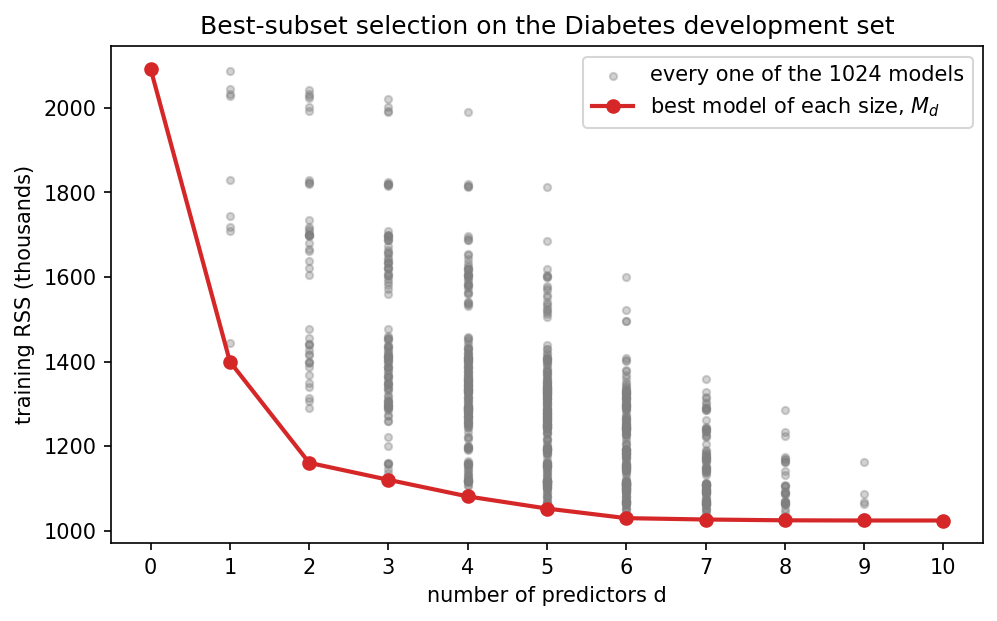

In [10]:
def best_subset(Z, y):
    '''Best-subset selection: for every size d, try every set of d columns and keep the one with the smallest RSS.

    returns best_cols : list of p+1 lists, best_cols[d] = the column numbers of the best model of size d
            best_rss  : array of p+1 numbers, the RSS of those models
            all_sizes, all_rss : the size and RSS of EVERY model tried (for the plot)
    '''
    p = Z.shape[1]
    best_cols, best_rss, all_sizes, all_rss = [], [], [], []
    for d in range(p + 1):
        smallest, winner = np.inf, None
        for cols in itertools.combinations(range(p), d):       # every set of d column numbers
            r = rss(Z, y, list(cols))
            all_sizes.append(d)
            all_rss.append(r)
            if r < smallest:                                    # a new best model of this size
                smallest, winner = r, list(cols)
        best_cols.append(winner)
        best_rss.append(smallest)
    return best_cols, np.array(best_rss), np.array(all_sizes), np.array(all_rss)


bs_cols, bs_rss, all_sizes, all_rss = best_subset(Z_dev, y_dev)

# checks (there is no library version of best subset, so we check its properties)
print("models fitted:", len(all_rss), "   equal to 2^10:", len(all_rss) == 2 ** p)
print("RSS never goes up as d grows        :", np.all(np.diff(bs_rss) <= 0))
print("M_10 is the full OLS model of Part 2:", bs_cols[p] == list(range(p)) and np.isclose(bs_rss[p], rss_full))
print("M_0 is the intercept-only model     :", bs_cols[0] == [] and np.isclose(bs_rss[0], tss))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.scatter(all_sizes, all_rss / 1000, s=12, color="tab:grey", alpha=0.35, label="every one of the 1024 models")
ax.plot(range(p + 1), bs_rss / 1000, "o-", color="tab:red", lw=2, label="best model of each size, $M_d$")
ax.set_xticks(range(p + 1))
ax.set_xlabel("number of predictors d")
ax.set_ylabel("training RSS (thousands)")
ax.set_title("Best-subset selection on the Diabetes development set")
ax.legend()
plt.show()

**Line by line**

- `itertools.combinations(range(p), d)` : produces every set of `d` numbers taken from `0, 1, ..., 9`, each set once,
  as a tuple. For `d = 2` it gives `(0, 1), (0, 2), ..., (8, 9)`, 45 tuples in all. For `d = 0` it gives one empty
  tuple, the intercept-only model.
- `list(cols)` : turns the tuple into a list, because NumPy treats a list as "pick these columns".
- `smallest, winner = np.inf, None` : start every size with an RSS of "infinity", so the first model tried always
  becomes the current winner.
- `all_sizes` and `all_rss` record every one of the 1024 models, only so that we can draw them all.
- `np.diff(bs_rss)` : the differences between neighbouring entries. All of them must be $\le 0$.
- The checks replace a library comparison: scikit-learn has no best-subset function, so we check what must be true.
- `all_rss / 1000` : the RSS values are around a million; plotting them in thousands keeps the axis labels short.

**Reading the plot.** Each grey column of dots shows all the models of one size: 10 models with one predictor,
45 with two, 120 with three, and so on, 1024 in all. The red line connects the lowest dot in each column. It falls
steeply at first (`bmi` alone already cuts the RSS from 2.09 million to 1.40 million), then flattens out after about
five or six predictors, and it **never goes up**, as 2c promised. The flat part is exactly where the training RSS stops
being useful for choosing.

### 3b. The eleven candidate models and their scores

In [11]:
rows = []
for d in range(p + 1):
    rows.append({"d": d,
                 "features": ", ".join(feature_names[bs_cols[d]]),
                 "RSS": int(round(bs_rss[d])),
                 **criteria(bs_rss[d], d)})              # adds the four scores as four more columns
bs_table = pd.DataFrame(rows).set_index("d")
bs_table

,features,RSS,AIC,BIC,Cp,adj R^2
d,,,,,,
0,,2092046,3068.5763,3072.4428,347.6762,0.0000
1,bmi,1399575,2928.6796,2936.4125,118.4132,0.3291
2,"bmi, s5",1160510,2864.5594,2876.1588,40.5731,0.4421
3,"bmi, bp, s5",1120274,2854.1035,2869.5694,29.1357,0.4599
4,"bmi, bp, s1, s5",1081026,2843.5143,2862.8467,18.0278,0.4773
5,"sex, bmi, bp, s3, s5",1052341,2836.0210,2859.2199,10.4481,0.4897
6,"sex, bmi, bp, s1, s2, s5",1029653,2830.3273,2857.3926,4.8710,0.4993
7,"sex, bmi, bp, s1, s2, s4, s5",1026434,2831.2219,2862.1536,5.7959,0.4994
8,"sex, bmi, bp, s1, s2, s4, s5, s6",1024504,2832.5578,2867.3560,7.1516,0.4989


**Line by line**

- `feature_names[bs_cols[d]]` : the names of the features in $M_d$ (fancy indexing with a list of positions).
- `**criteria(bs_rss[d], d)` : the two stars **unpack** a dictionary inside another dictionary. The four keys of the
  dictionary returned by `criteria` become four more entries of the row, so the table gets the columns `AIC`, `BIC`,
  `Cp` and `adj R^2`.
- `.set_index("d")` : uses the size $d$ as the row label.

**Reading the table.**

- `bmi` is the single best predictor, `bmi, s5` the best pair, and `bmi, bp, s5` the best three.
- Look closely at $M_4$ and $M_5$. $M_4$ is `bmi, bp, s1, s5`, but $M_5$ is `sex, bmi, bp, s3, s5`: **`s1` has
  left** and two new features have arrived. The best model of size 5 is *not* the best model of size 4 plus one
  feature. Best subsets do not have to be **nested**. Remember this; it is exactly where the stepwise methods of Part 4
  will differ.
- From $d = 6$ to $d = 10$ the RSS hardly changes (1.030 to 1.024 million), while each criterion's penalty keeps
  growing. That is why the criteria start to get worse again after six or seven predictors.

### 3c. Which size do the four criteria choose?

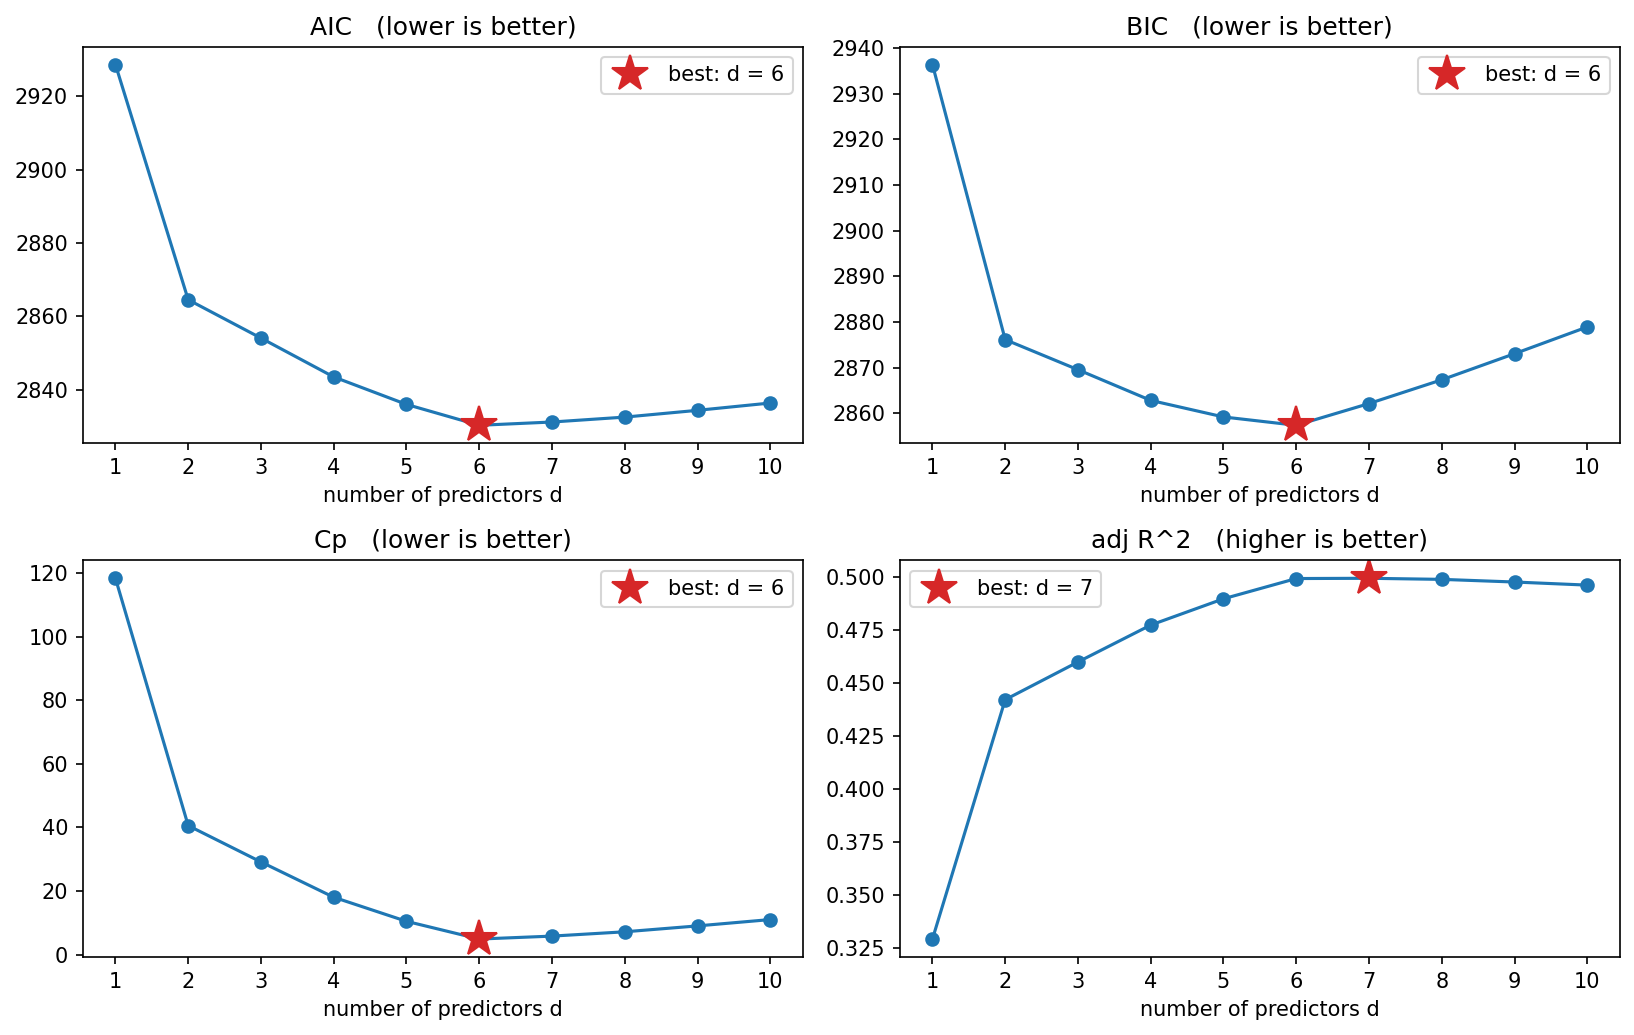

,chosen d,features
criterion,,
AIC,6,"sex, bmi, bp, s1, s2, s5"
BIC,6,"sex, bmi, bp, s1, s2, s5"
Cp,6,"sex, bmi, bp, s1, s2, s5"
adj R^2,7,"sex, bmi, bp, s1, s2, s4, s5"


In [12]:
best_d = {"AIC": bs_table["AIC"].idxmin(),               # lower is better
          "BIC": bs_table["BIC"].idxmin(),
          "Cp": bs_table["Cp"].idxmin(),
          "adj R^2": bs_table["adj R^2"].idxmax()}        # higher is better

sizes = np.arange(1, p + 1)                               # start at d = 1: the empty model is far off the scale
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.ravel(), best_d):
    ax.plot(sizes, bs_table.loc[sizes, name], "o-", color="tab:blue")
    ax.plot(best_d[name], bs_table.loc[best_d[name], name], "*", color="tab:red", markersize=18,
            label=f"best: d = {best_d[name]}")
    ax.set_xticks(sizes)
    ax.set_xlabel("number of predictors d")
    ax.set_title(name + ("   (higher is better)" if name == "adj R^2" else "   (lower is better)"))
    ax.legend()
plt.tight_layout()
plt.show()

chosen = pd.DataFrame([{"criterion": name, "chosen d": d, "features": ", ".join(feature_names[bs_cols[d]])}
                       for name, d in best_d.items()]).set_index("criterion")
chosen

**Line by line**

- `.idxmin()` and `.idxmax()` : the **row label** (here the size $d$) of the smallest or largest value in a column,
  as in Practical 4.
- `axes.ravel()` : `plt.subplots(2, 2)` returns a $2 \times 2$ grid of panels; `ravel` lays it out as a flat list of
  four, so one loop can visit them all. Looping over the dictionary `best_d` gives its four keys in order.
- `bs_table.loc[sizes, name]` : the rows with labels $1, \dots, 10$ of one column.
- The red star is drawn at the chosen size, on top of the curve.

**Reading the plots and the table.**

- **AIC, BIC and $C_p$ all choose $d = 6$**: `sex, bmi, bp, s1, s2, s5`. $C_p$ at $d = 6$ is 4.87, below its number
  of parameters (7), which is what a good model should show.
- **Adjusted $R^2$ chooses $d = 7$**, adding `s4`. But look at the numbers: 0.4993 for $d = 6$ against 0.4994 for
  $d = 7$. The curve is completely flat there, and adjusted $R^2$ has the **weakest** penalty of the four, so it tends
  to choose the **largest** model.
- **BIC has the strongest penalty** and tends to choose the **smallest** model. Here it agrees with AIC, but its
  curve rises much more steeply to the right of the minimum. If you change `SEED_TEST` you will find splits where BIC
  picks 5 predictors while adjusted $R^2$ picks 8: the criteria really do disagree.
- Notice that the chosen model keeps **both** `s1` and `s2`. Subset selection decides which predictors are *in*, but
  inside the model it is still plain OLS, so the two correlated coefficients are still large with opposite signs.
  Shrinkage (Part 5) attacks exactly that problem.

## Part 4: Forward and backward stepwise selection

### 4a. Greedy shortcuts

Best subset fits $2^p$ models. That number doubles with every extra predictor: about a thousand for $p = 10$, a million
for $p = 20$, and $3.6 \times 10^{16}$ for the 55 predictors we will meet in Part 7. **Stepwise selection** builds
the models one step at a time instead, and never looks back:

- **Forward stepwise.** Start with no predictors. At every step, try adding each predictor that is not yet in the
  model, and keep the one that lowers the RSS the most. Stop when all $p$ are in.
- **Backward stepwise.** Start with all $p$ predictors. At every step, try removing each predictor in the model, and
  remove the one whose removal raises the RSS the least. Stop when none are left.

Both give one model of every size $d = 0, 1, \dots, p$, just like best subset, and the same four criteria then choose
between them. Forward selection fits $1 + p + (p-1) + \dots + 1 = 1 + p(p+1)/2$ models, and backward selection the
same number: 56 instead of 1024 for $p = 10$. The price is that they are **greedy**: once forward selection has added
a predictor, it can never take it out again, so it can miss the best subset.

In [13]:
def forward_stepwise(Z, y):
    '''Forward stepwise selection: start empty, repeatedly add the column that lowers RSS the most.

    returns path   : list of p+1 lists, path[d] = the (sorted) columns of the model with d predictors
            n_fits : how many OLS models were fitted
    '''
    p = Z.shape[1]
    chosen, path, n_fits = [], [[]], 1                  # the empty model counts as one fit
    while len(chosen) < p:
        candidates = [j for j in range(p) if j not in chosen]
        rss_each = [rss(Z, y, chosen + [j]) for j in candidates]
        n_fits += len(candidates)
        chosen = chosen + [candidates[int(np.argmin(rss_each))]]   # add the best candidate
        path.append(sorted(chosen))
    return path, n_fits


def backward_stepwise(Z, y):
    '''Backward stepwise selection: start full, repeatedly remove the column whose removal raises RSS the least.'''
    p = Z.shape[1]
    chosen, path, n_fits = list(range(p)), [list(range(p))], 1    # the full model counts as one fit
    while chosen:
        rss_each = [rss(Z, y, [c for c in chosen if c != j]) for j in chosen]
        n_fits += len(chosen)
        drop = chosen[int(np.argmin(rss_each))]                    # removing this one hurts the least
        chosen = [c for c in chosen if c != drop]
        path.append(chosen)
    return path[::-1], n_fits                                      # reverse, so path[d] has d predictors


fw_cols, fw_fits = forward_stepwise(Z_dev, y_dev)
bw_cols, bw_fits = backward_stepwise(Z_dev, y_dev)

added = [(set(fw_cols[d]) - set(fw_cols[d - 1])).pop() for d in range(1, p + 1)]
removed = [(set(bw_cols[d]) - set(bw_cols[d - 1])).pop() for d in range(p, 0, -1)]
print("forward adds the features in the order   :", " > ".join(feature_names[added]))
print("backward removes the features in the order:", " > ".join(feature_names[removed]))
print(f"\nmodels fitted: best subset {len(all_rss)},  forward {fw_fits},  backward {bw_fits}")

forward adds the features in the order   : bmi > s5 > bp > s1 > sex > s2 > s4 > s6 > s3 > age
backward removes the features in the order: age > s3 > s6 > s4 > s2 > sex > s1 > bp > s5 > bmi

models fitted: best subset 1024,  forward 56,  backward 56


**Line by line**

- `candidates = [j for j in range(p) if j not in chosen]` : a list comprehension that keeps the column numbers not
  yet in the model.
- `rss_each = [rss(Z, y, chosen + [j]) for j in candidates]` : the RSS of the current model plus one more column,
  for every candidate. `chosen + [j]` makes a **new** list and leaves `chosen` unchanged.
- `int(np.argmin(rss_each))` : the **position** of the smallest RSS in the list, so `candidates[...]` is the winning
  column.
- `while chosen:` : an empty list counts as `False` in Python, so the backward loop runs until no columns are left.
- `[c for c in chosen if c != j]` : the current model with column `j` taken out.
- `path[::-1]` : the backward path is built from big to small; reversing it makes `path[d]` the model with $d$
  predictors, exactly like `bs_cols[d]`.
- `set(a) - set(b)` : the elements of `a` that are not in `b`. Between two neighbouring models there is exactly one,
  and `.pop()` takes it out of the set. This recovers the order in which features were added or removed.

**Reading the output.** Forward selection adds `bmi` first, then `s5`, `bp`, `s1`, `sex`, `s2`, and so on. Backward
selection throws out `age` first and `bmi` last. The two orders are exact mirror images here, so the two methods
produce the same models; that is a coincidence of this dataset, not a rule. Both needed **56** fits, against 1024 for
best subset.

### 4b. Checking against `SequentialFeatureSelector`

scikit-learn's `SequentialFeatureSelector` does forward and backward selection. Normally it scores every candidate
by cross-validation. Our functions score by the RSS on the training rows, so to compare like with like we pass
`cv=[(rows, rows)]`: a "cross-validation" with a single split whose training part and validation part are **both**
all the rows. Then the library scores every candidate by its training MSE, which is RSS divided by $n$, so it ranks
the candidates exactly as we do.

In [14]:
rows_all = np.arange(n_dev)                            # 0, 1, ..., 352: every development row
forward_ok, backward_ok = [], []
for d in range(1, p):                                  # the library needs d < p
    for direction, path, ok in [("forward", fw_cols, forward_ok), ("backward", bw_cols, backward_ok)]:
        sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=d, direction=direction,
                                        scoring="neg_mean_squared_error", cv=[(rows_all, rows_all)])
        sfs.fit(Z_dev, y_dev)
        ok.append(np.array_equal(np.flatnonzero(sfs.get_support()), path[d]))

print("forward  selection matches SequentialFeatureSelector for d = 1 to 9:", all(forward_ok))
print("backward selection matches SequentialFeatureSelector for d = 1 to 9:", all(backward_ok))

forward  selection matches SequentialFeatureSelector for d = 1 to 9: True
backward selection matches SequentialFeatureSelector for d = 1 to 9: True


**Line by line**

- `cv=[(rows_all, rows_all)]` : the `cv` argument accepts a list of `(train_rows, validation_rows)` pairs, the same
  format as our folds in Practical 4. One pair, with the same rows twice, means "fit on all rows, score on the same
  rows".
- `scoring="neg_mean_squared_error"` : scikit-learn always **maximises** a score, so it uses minus the MSE. Maximising
  $-\text{MSE}$ is the same as minimising the MSE, and therefore the RSS.
- `n_features_to_select=d` with `range(1, p)` : the library refuses $d = p$ (selecting every feature is not a
  selection), so we check $d = 1$ to 9. Sizes 0 and 10 are trivially the same for every method.
- `sfs.get_support()` : a boolean mask with `True` for the selected columns; `np.flatnonzero` turns it into the list of
  their positions, which we compare with our own.
- The list `ok` is filled through its name inside the loop: `forward_ok` and `backward_ok` are the same list objects,
  so appending to `ok` appends to them.

**Reading the output.** Both lines print `True`: for every size, our greedy functions pick exactly the same features
as the library.

### 4c. Best subset against stepwise, and the cost of each

In [15]:
rows = []
for d in range(p + 1):
    rows.append({"d": d,
                 "best subset": ", ".join(feature_names[bs_cols[d]]),
                 "forward": ", ".join(feature_names[fw_cols[d]]),
                 "backward": ", ".join(feature_names[bw_cols[d]]),
                 "all agree": bs_cols[d] == fw_cols[d] == bw_cols[d],
                 "RSS best subset": int(round(bs_rss[d])),
                 "RSS forward": int(round(rss(Z_dev, y_dev, fw_cols[d])))})
comparison = pd.DataFrame(rows).set_index("d")
display(comparison)

cost = pd.DataFrame({"p": [10, 20, 55]})
cost["best subset: 2^p fits"] = [2 ** int(q) for q in cost["p"]]
cost["stepwise: 1 + p(p+1)/2 fits"] = [1 + int(q) * (int(q) + 1) // 2 for q in cost["p"]]
display(cost)

years = 2 ** 55 * 0.001 / (60 * 60 * 24 * 365.25)
print(f"best subset with 55 predictors, at one millisecond per fit, would take about {years:,.0f} years")

,best subset,forward,backward,all agree,RSS best subset,RSS forward
d,,,,,,
0,,,,True,2092046,2092046
1,bmi,bmi,bmi,True,1399575,1399575
2,"bmi, s5","bmi, s5","bmi, s5",True,1160510,1160510
3,"bmi, bp, s5","bmi, bp, s5","bmi, bp, s5",True,1120274,1120274
4,"bmi, bp, s1, s5","bmi, bp, s1, s5","bmi, bp, s1, s5",True,1081026,1081026
5,"sex, bmi, bp, s3, s5","sex, bmi, bp, s1, s5","sex, bmi, bp, s1, s5",False,1052341,1064233
6,"sex, bmi, bp, s1, s2, s5","sex, bmi, bp, s1, s2, s5","sex, bmi, bp, s1, s2, s5",True,1029653,1029653
7,"sex, bmi, bp, s1, s2, s4, s5","sex, bmi, bp, s1, s2, s4, s5","sex, bmi, bp, s1, s2, s4, s5",True,1026434,1026434
8,"sex, bmi, bp, s1, s2, s4, s5, s6","sex, bmi, bp, s1, s2, s4, s5, s6","sex, bmi, bp, s1, s2, s4, s5, s6",True,1024504,1024504


,p,best subset: 2^p fits,stepwise: 1 + p(p+1)/2 fits
0,10,1024,56
1,20,1048576,211
2,55,36028797018963968,1541


best subset with 55 predictors, at one millisecond per fit, would take about 1,141,684 years


**Line by line**

- `bs_cols[d] == fw_cols[d] == bw_cols[d]` : Python allows chained comparisons; this is `True` only if all three
  lists are equal.
- `display(...)` : prints a table nicely in the middle of a cell. Normally only the **last** line of a cell is shown,
  so to show two tables we call `display` for each.
- `2 ** int(q)` : powers of two. `int(q)` turns the NumPy number into an ordinary Python integer, which can be as
  large as we like.
- `//` : integer division, so the number of fits stays a whole number.
- `f"{years:,.0f}"` : the comma in the format adds thousands separators, and `.0f` means no decimals.

**Reading the tables.**

- The three methods agree at **every size except $d = 5$**. There, forward and backward stepwise give
  `sex, bmi, bp, s1, s5` (RSS 1,064,233), while best subset finds `sex, bmi, bp, s3, s5` (RSS 1,052,341). Forward
  selection added `s1` at step 4 and is never allowed to remove it, so at step 5 it can only add `sex`. Best subset is
  free to throw `s1` out. This is exactly the non-nested pair we noticed in 3b.
- At the size the criteria actually chose ($d = 6$), all three methods agree, so stepwise selection reaches the same
  final model with 56 fits instead of 1024.
- The cost table is the real reason stepwise methods exist. With 55 predictors, best subset would need about
  $3.6 \times 10^{16}$ fits, which at a millisecond each is more than a million years. Forward stepwise needs 1541.

## Part 5: Shrinkage: ridge regression and the lasso

Subset selection is an **all-or-nothing** decision: a predictor is either in, with its full OLS coefficient, or out.
A small change in the data can flip a predictor from in to out (we saw `s1` leave between $M_4$ and $M_5$), so the
fitted model can jump. **Shrinkage** is gentler. It keeps every predictor but adds a penalty that pulls all the
coefficients towards zero, continuously, by an amount we control with $\lambda$.

### 5a. Ridge regression in closed form

Ridge regression chooses the coefficients that minimise

$$\sum_{i=1}^{n} \big(y_i - \beta_0 - x_i^{\top}\beta\big)^2 \;+\; \lambda \sum_{j=1}^{p} \beta_j^2 .$$

The first part is the RSS, as in OLS. The second part punishes large coefficients. The intercept $\beta_0$ is **not**
penalised: it only sets the overall level of the predictions. With $\lambda = 0$ ridge is OLS; as $\lambda$ grows, the
coefficients are pulled closer and closer to zero.

**The closed form.** Centre the features and the target (subtract their means). Setting the derivative with respect to
$\beta$ to zero gives $-2X^{\top}(y - X\beta) + 2\lambda\beta = 0$, that is

$$(X^{\top}X + \lambda I)\,\beta = X^{\top}y, \qquad \hat\beta = (X^{\top}X + \lambda I)^{-1}X^{\top}y,
\qquad \hat\beta_0 = \bar y - \bar x^{\top}\hat\beta .$$

The only difference from the normal equations of OLS is the $+\lambda I$: **$\lambda$ is added to the diagonal**.

**Why this helps with correlated predictors.** When some columns are nearly linear combinations of others, the matrix
$X^{\top}X$ is nearly singular: one of its eigenvalues is close to zero. Solving the normal equations then divides by
that tiny number, which blows up the noise in that direction into huge coefficients. Adding $\lambda$ to the diagonal
adds $\lambda$ to **every** eigenvalue, so nothing is close to zero any more, and the solution is stable.

In [16]:
def ridge_fit(Z, y, lam):
    '''Ridge regression in closed form. The intercept is not penalised.

    returns (b0, b), the intercept and the coefficients
    '''
    z_mean, y_mean = Z.mean(axis=0), y.mean()
    Zc, yc = Z - z_mean, y - y_mean                                   # centre the features and the target
    b = np.linalg.solve(Zc.T @ Zc + lam * np.eye(Z.shape[1]), Zc.T @ yc)   # (Z^T Z + lam I) b = Z^T y
    b0 = y_mean - z_mean @ b                                          # the intercept puts the line through the means
    return b0, b


# the library check
for lam in [0.1, 10, 1000]:
    b0, b = ridge_fit(Z_dev, y_dev, lam)
    lib = Ridge(alpha=lam).fit(Z_dev, y_dev)
    print(f"lambda = {lam:>6}:  same coefficients as Ridge: {np.allclose(b, lib.coef_)},"
          f"  same intercept: {np.isclose(b0, lib.intercept_)}")
print("lambda = 0 gives back OLS:", np.allclose(ridge_fit(Z_dev, y_dev, 0.0)[1], b_ols))

eigenvalues = np.linalg.eigvalsh(Z_dev.T @ Z_dev)            # eigenvalues of Z^T Z, smallest first
print(f"\neigenvalues of Z^T Z: smallest {eigenvalues[0]:.2f}, largest {eigenvalues[-1]:.2f}")

rows = []
for lam in [0, 1, 10, 30, 100, 1000]:
    b0, b = ridge_fit(Z_dev, y_dev, lam)
    rows.append({"lambda": lam, "s1": b[4], "s2": b[5], "s1 + s2": b[4] + b[5],
                 "smallest eigenvalue of Z^T Z + lambda I": eigenvalues[0] + lam})
pd.DataFrame(rows).set_index("lambda")

lambda =    0.1:  same coefficients as Ridge: True,  same intercept: True
lambda =     10:  same coefficients as Ridge: True,  same intercept: True
lambda =   1000:  same coefficients as Ridge: True,  same intercept: True
lambda = 0 gives back OLS: True

eigenvalues of Z^T Z: smallest 2.65, largest 1407.19


,s1,s2,s1 + s2,smallest eigenvalue of Z^T Z + lambda I
lambda,,,,
0,-40.4625,23.2797,-17.1828,2.6497
1,-30.2374,14.9589,-15.2786,3.6497
10,-10.8716,-0.6601,-11.5316,12.6497
30,-5.8307,-4.1921,-10.0227,32.6497
100,-2.9667,-4.4126,-7.3794,102.6497
1000,0.6215,-0.0235,0.5980,1002.6497


**Line by line**

- `Zc, yc = Z - z_mean, y - y_mean` : centring. For the standardised `Z_dev` the column means are already 0, so this
  changes nothing and the intercept comes out as $\bar y$, the formula on the steps sheet. We still centre inside the
  function so that it is also correct for data whose columns do not have mean exactly 0, such as the bootstrap samples
  of Part 7. This is also exactly what scikit-learn's `Ridge` does.
- `lam * np.eye(Z.shape[1])` : `np.eye(10)` is the $10 \times 10$ identity matrix $I$, so this is $\lambda I$.
- `np.linalg.solve(...)` : solves $(Z^{\top}Z + \lambda I)\,b = Z^{\top}y$, the same tool as in `ols_fit`.
- `b0 = y_mean - z_mean @ b` : the intercept that makes the fitted plane pass through the point of means.
- `Ridge(alpha=lam)` : scikit-learn calls $\lambda$ `alpha`. Its objective is exactly ours (RSS plus
  $\alpha\sum\beta_j^2$, intercept not penalised), so the numbers must agree.
- `f"{lam:>6}"` : prints `lam` right-aligned in 6 characters, so the printed lines line up neatly.
- `np.linalg.eigvalsh(M)` : the eigenvalues of a symmetric matrix, sorted from smallest to largest.

**Reading the output.**

- All the checks print `True`: our function is exactly `Ridge`, and $\lambda = 0$ gives back OLS.
- The eigenvalues of $Z^{\top}Z$ run from about **2.6** to about **1407**. The tiny one belongs to a combination of the
  features that hardly varies across patients, mostly `s1` against `s2`, `s3` and `s5`. Medically that makes sense:
  total cholesterol is roughly LDL plus HDL plus a part linked to triglycerides, so these four columns are almost
  linearly dependent.
- In the table, watch `s1` and `s2` as $\lambda$ grows. At $\lambda = 0$ they are $-40.5$ and $+23.3$. Already at
  $\lambda = 10$ the wild opposite signs are gone, and from about $\lambda = 30$ the two coefficients are small and
  **similar** ($-5.8$ and $-4.2$): ridge **shares the weight** between the correlated pair instead of letting them
  fight. By
  $\lambda = 1000$ both are nearly zero.
- The last column shows the reason. Adding $\lambda$ lifts the smallest eigenvalue from 2.6 to 12.6 at $\lambda = 10$
  and to 102.6 at $\lambda = 100$, so the system is no longer close to singular.

### 5b. The lasso, and the soft-thresholding function

The lasso changes one thing: it penalises the **absolute values** of the coefficients instead of their squares. In
scikit-learn's scaling it minimises

$$\frac{1}{2n}\sum_{i=1}^{n} \big(y_i - \beta_0 - x_i^{\top}\beta\big)^2 \;+\; \lambda \sum_{j=1}^{p} \lvert\beta_j\rvert .$$

(The factor $\frac{1}{2n}$ in front of the RSS only changes the scale of $\lambda$. It means that a lasso $\lambda$ and
a ridge $\lambda$ are **not** on the same scale, which is why their grids in Part 6 are different.)

The absolute value has a sharp corner at zero, so there is no derivative there and **no closed-form solution**. But
there is a neat trick. Suppose all the coefficients except $\beta_j$ are held fixed. Then the problem in the single
number $\beta_j$ is easy. Write $r^{(j)}$ for the residual of the model **without** feature $j$,

$$r^{(j)}_i = y_i - \bar y - \sum_{k \ne j} x_{ik}\beta_k, \qquad\text{and}\qquad
\rho_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}\, r^{(j)}_i$$

for how strongly feature $j$ lines up with what is still unexplained. For a standardised feature
($\frac{1}{n}\sum_i x_{ij}^2 = 1$) the one-dimensional problem becomes
$\tfrac12\beta_j^2 - \rho_j\beta_j + \lambda\lvert\beta_j\rvert$ plus a constant, and its minimum is at

$$\beta_j = S(\rho_j, \lambda), \qquad
S(z, \lambda) = \operatorname{sign}(z)\,\max(\lvert z\rvert - \lambda,\, 0) =
\begin{cases} z - \lambda & \text{if } z > \lambda,\\ 0 & \text{if } \lvert z\rvert \le \lambda,\\ z + \lambda & \text{if } z < -\lambda.\end{cases}$$

$S$ is called the **soft-thresholding** function. Without a penalty the answer would be $\beta_j = \rho_j$. The lasso
moves it towards zero by $\lambda$, and if that would carry it past zero, it **stops at exactly zero**.

S(z, 1) for z = -2.5, -1, -0.3, 0, 0.4, 1, 1.7 : [-1.5  0.   0.   0.   0.   0.   0.7]


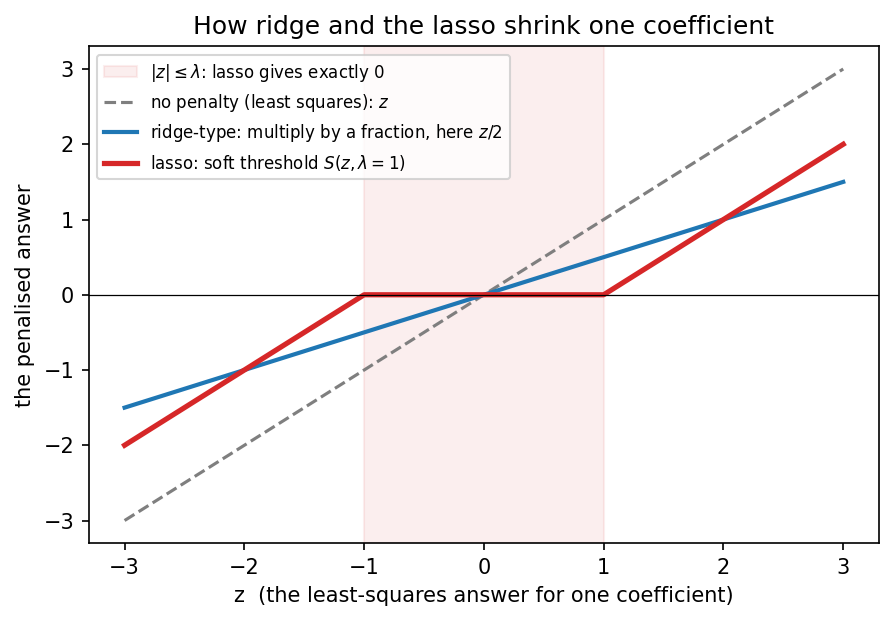

In [17]:
def soft_threshold(z, lam):
    '''S(z, lam): move z towards 0 by lam, and stop at exactly 0 if |z| <= lam.'''
    return np.where(np.abs(z) > lam, z - np.sign(z) * lam, 0.0)


print("S(z, 1) for z = -2.5, -1, -0.3, 0, 0.4, 1, 1.7 :",
      soft_threshold(np.array([-2.5, -1.0, -0.3, 0.0, 0.4, 1.0, 1.7]), 1.0))

z = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(6.8, 4.3))
ax.axvspan(-1, 1, color="tab:red", alpha=0.08, label=r"$|z| \leq \lambda$: lasso gives exactly 0")
ax.plot(z, z, color="tab:grey", linestyle="dashed", label="no penalty (least squares): $z$")
ax.plot(z, z / 2, color="tab:blue", lw=2, label="ridge-type: multiply by a fraction, here $z/2$")
ax.plot(z, soft_threshold(z, 1.0), color="tab:red", lw=2.5, label=r"lasso: soft threshold $S(z, \lambda=1)$")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("z  (the least-squares answer for one coefficient)")
ax.set_ylabel("the penalised answer")
ax.set_title("How ridge and the lasso shrink one coefficient")
ax.legend(fontsize=8, loc="upper left")
plt.show()

**Line by line**

- `np.where(condition, a, b)` : element by element, takes `a` where the condition is `True` and `b` where it is
  `False`. So: if $\lvert z\rvert > \lambda$, move $z$ towards zero by $\lambda$ (`z - sign(z) * lam`); otherwise
  return exactly 0. This is the three-case formula above, written in one line. (Writing
  `np.sign(z) * np.maximum(np.abs(z) - lam, 0)` gives the same numbers, but it turns small negative inputs into a
  "negative zero" $-0.0$, which prints confusingly.)
- `ax.axvspan(-1, 1, ...)` : shades the vertical band between $-1$ and $1$, the **dead zone** where the lasso answer
  is zero.
- `r"$|z| \leq \lambda$"` : the `r` in front makes a **raw string**, so the backslashes reach matplotlib, which
  draws the text between dollar signs as a formula.

**Reading the output and the plot.** Inputs between $-1$ and $1$ all become exactly 0. Bigger inputs are moved
towards zero by exactly 1: $-2.5$ becomes $-1.5$, and $1.7$ becomes $0.7$.

The plot shows the essential difference between the two penalties. **Ridge** (blue) multiplies by a fraction: a
large coefficient is shrunk a lot, a small one a little, but **nothing ever reaches zero**. The **lasso** (red)
subtracts a fixed amount, and everything in the shaded band is set to **exactly zero**. That is where the zeros of the
lasso come from, and why the lasso does subset selection and shrinkage at the same time.

### 5c. The lasso by coordinate descent

**Coordinate descent** simply applies the one-coefficient solution over and over:

1. Start with all coefficients equal to 0.
2. **Sweep** over the features $j = 1, 2, \dots, p$. For each one, compute $\rho_j$ from the current residual and set
   $\beta_j \leftarrow S(\rho_j, \lambda)$.
3. Repeat the sweeps until no coefficient changes by more than a tiny tolerance ($10^{-8}$).

Every update can only lower the lasso objective, and because the objective is convex (a single valley, no false
minima) the sweeps end at the true minimum.

Two practical details. First, recomputing the residual from scratch for every $j$ would be slow, so we keep the
**full** residual $r = y - \bar y - X\beta$ up to date instead; the partial residual is then
$r^{(j)} = r + x_j\beta_j$, which gives $\rho_j = \frac1n x_j^{\top} r + \frac1n (x_j^{\top}x_j)\,\beta_j$. Second, we
divide by $\frac1n x_j^{\top}x_j$, which is exactly 1 for a standardised column; dividing makes the function correct
even when a column is not exactly standardised (a bootstrap sample in Part 7, for example).

In [18]:
def lasso_fit(Z, y, lam, b_start=None, tol=1e-8, max_sweeps=100000):
    '''Lasso by coordinate descent, with scikit-learn's scaling: (1/2n) RSS + lam * sum |b_j|.

    b_start : optional starting coefficients (a "warm start"); None means start from all zeros
    returns (b0, b), the intercept and the coefficients
    '''
    n, p = Z.shape
    z_mean, y_mean = Z.mean(axis=0), y.mean()
    Zc, yc = Z - z_mean, y - y_mean                 # centre, so the intercept can be found at the end
    col_sq = (Zc ** 2).mean(axis=0)                 # (1/n) x_j^T x_j for every column: 1 if standardised
    b = np.zeros(p) if b_start is None else b_start.copy()
    r = yc - Zc @ b                                 # the full residual of the current model

    for sweep in range(max_sweeps):
        biggest_change = 0.0
        for j in range(p):
            rho = Zc[:, j] @ r / n + col_sq[j] * b[j]           # (1/n) x_j^T r^(j), using the full residual
            new_bj = soft_threshold(rho, lam) / col_sq[j]
            change = new_bj - b[j]
            if change != 0.0:
                r -= Zc[:, j] * change                          # keep the residual up to date
                b[j] = new_bj
                biggest_change = max(biggest_change, abs(change))
        if biggest_change < tol:                                # a whole sweep with (almost) no change: done
            break

    b0 = y_mean - z_mean @ b
    return b0, b


# the library check
rows = []
for lam in [0.01, 0.1, 1, 5, 20]:
    b0, b = lasso_fit(Z_dev, y_dev, lam)
    lib = Lasso(alpha=lam, tol=1e-10, max_iter=100000).fit(Z_dev, y_dev)
    rows.append({"lambda": lam,
                 "same as Lasso": np.allclose(b, lib.coef_, atol=1e-6) and np.isclose(b0, lib.intercept_),
                 "largest difference": np.abs(b - lib.coef_).max(),
                 "zero coefficients": int(np.sum(b == 0))})
display(pd.DataFrame(rows).set_index("lambda"))

lam_max = np.max(np.abs(Z_dev.T @ (y_dev - y_dev.mean()))) / n_dev
print(f"lambda_max = {lam_max:.2f}")
print("every coefficient is 0 at lambda_max         :", np.all(lasso_fit(Z_dev, y_dev, lam_max)[1] == 0))
print("just below lambda_max, the non-zero ones are :",
      feature_names[lasso_fit(Z_dev, y_dev, 0.99 * lam_max)[1] != 0])

,same as Lasso,largest difference,zero coefficients
lambda,,,
0.01,True,4.0288e-07,0
0.10,True,4.4630e-07,0
1.00,True,2.4174e-09,3
5.00,True,1.9844e-09,5
20.00,True,4.8704e-10,7


lambda_max = 44.29
every coefficient is 0 at lambda_max         : True
just below lambda_max, the non-zero ones are : ['bmi']


**Line by line**

- `col_sq = (Zc ** 2).mean(axis=0)` : $\frac1n x_j^{\top}x_j$ for every column. For `Z_dev` all ten are exactly 1.
- `b_start.copy()` : a **warm start**. If we already know a good guess (for example the answer for a slightly
  different $\lambda$), starting from it saves many sweeps. Part 6 uses this. `.copy()` makes sure we do not change
  the caller's array.
- `rho = Zc[:, j] @ r / n + col_sq[j] * b[j]` : the formula from the text. `Zc[:, j] @ r` is the dot product of column
  $j$ with the full residual; adding back $\frac1n x_j^{\top}x_j\,\beta_j$ removes feature $j$'s own contribution.
- `r -= Zc[:, j] * change` : if $\beta_j$ goes up by `change`, the predictions go up by `Zc[:, j] * change`, so the
  residual goes down by the same amount. One short vector operation instead of recomputing `Zc @ b`.
- `if biggest_change < tol: break` : stop as soon as a full sweep moves no coefficient by more than $10^{-8}$.
- `Lasso(alpha=lam, tol=1e-10, max_iter=100000)` : scikit-learn's lasso, also by coordinate descent. Its default
  tolerance is loose, so we tighten it to make both functions converge to the same answer.
- `np.allclose(..., atol=1e-6)` : two iterative methods stop at slightly different points, so we accept differences
  below $10^{-6}$.
- `lam_max` : at $\beta = 0$ the residual is $y - \bar y$, so $\rho_j = \frac1n x_j^{\top}(y - \bar y)$. If
  $\lvert\rho_j\rvert \le \lambda$ for **every** $j$, soft thresholding keeps every coefficient at 0, and $\beta = 0$
  is the answer. So the smallest $\lambda$ that makes the whole model zero is
  $\lambda_{\max} = \max_j \lvert\frac1n x_j^{\top}(y - \bar y)\rvert$.

**Reading the output.**

- At every $\lambda$ our coefficients match `Lasso` to better than $10^{-6}$.
- The number of zero coefficients grows with $\lambda$: none at $\lambda = 0.01$ and $0.1$, 3 at $\lambda = 1$, 5 at
  $\lambda = 5$ and 7 at $\lambda = 20$. Ridge never produces a single exact zero.
- $\lambda_{\max} \approx 44.3$. At $\lambda_{\max}$ the whole model is zero; just below it, only `bmi` is non-zero.
  `bmi` is the feature most correlated with the target, the same feature that best subset and forward selection
  picked first.

## Part 6: Shrinkage paths, and choosing $\lambda$ by cross-validation

### 6a. The shrinkage paths

A **shrinkage path** shows every coefficient as $\lambda$ runs from almost nothing (close to OLS) to very large
(everything shrunk to zero). We use 100 values of $\lambda$ spaced evenly on a log scale: from $10^{-2}$ to $10^{5}$
for ridge and from $10^{-2}$ to $10^{2}$ for the lasso (different ranges, because of the $\frac{1}{2n}$ in the lasso
objective).

For the lasso we use **warm starts**: we go from the largest $\lambda$ to the smallest and start each fit from the
answer for the previous $\lambda$, which is already very close.

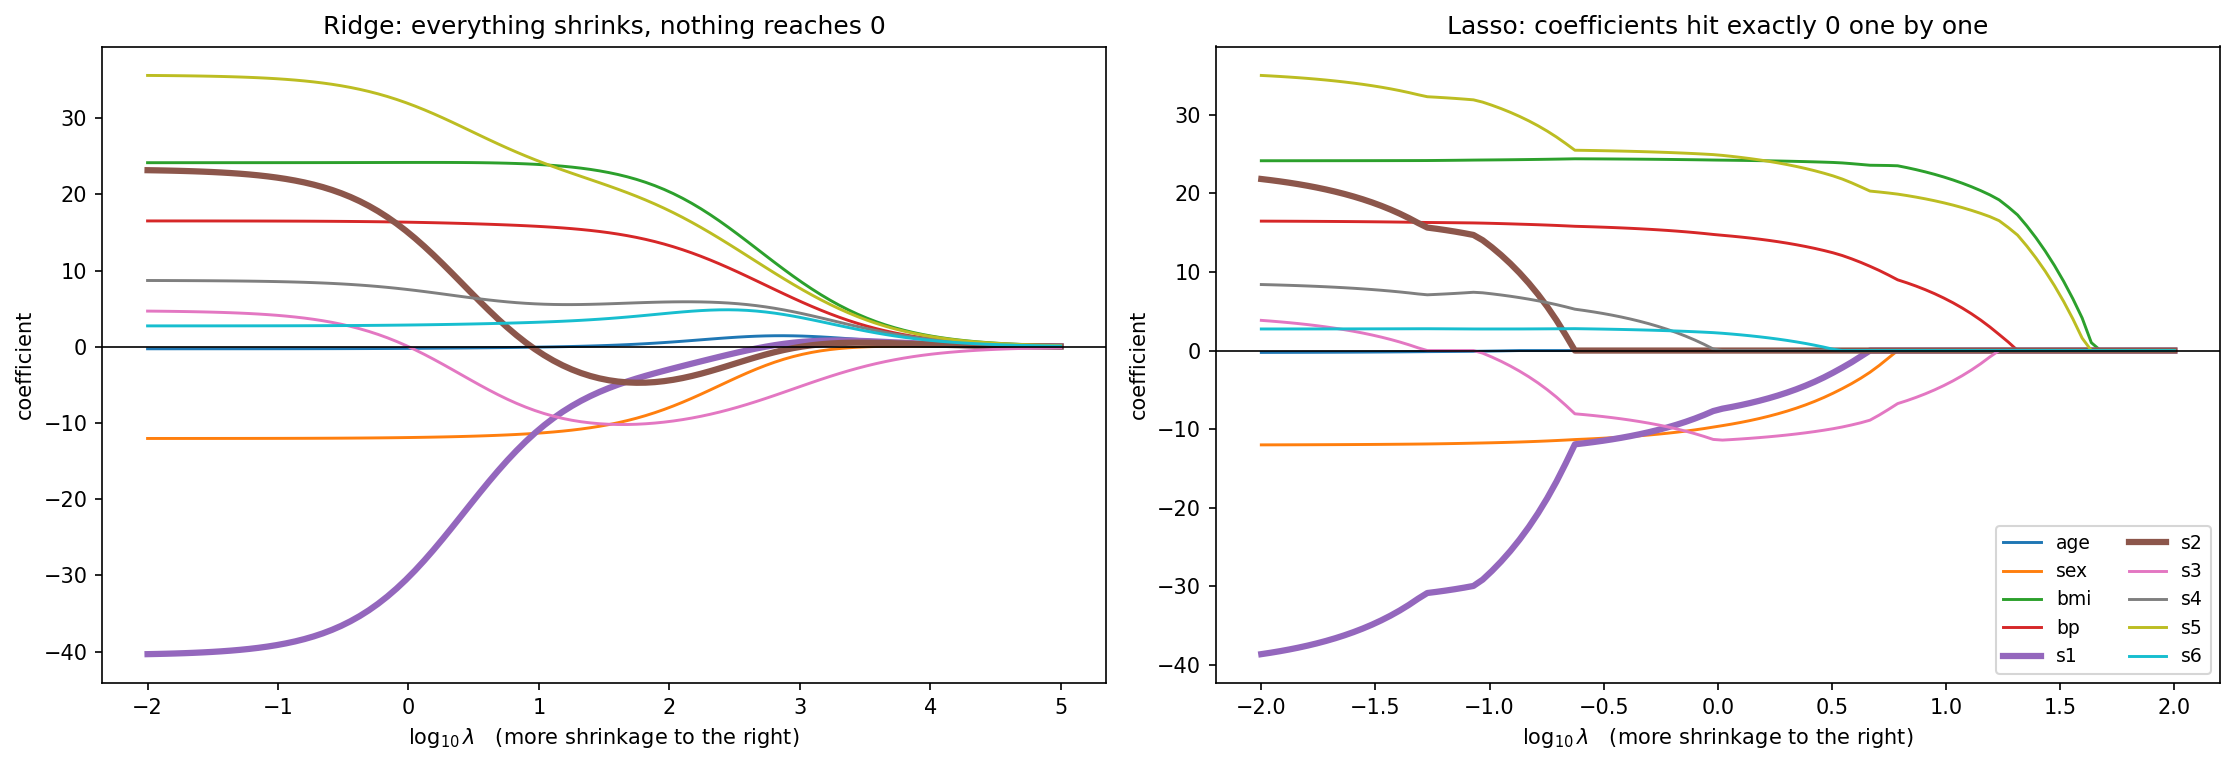

lasso: the largest lambda at which each coefficient is still non-zero
(the order in which the features drop out as lambda grows, last to drop out first):


,bmi,s5,bp,s3,sex,s1,s6,s4,s2,age
lambda,43.2876,39.4421,20.5651,15.5568,5.5908,4.2292,3.1993,0.9545,0.2154,0.1233


In [19]:
def ridge_path(Z, y, lams):
    '''Ridge fits for every lambda. returns (b0s, B): B[i] = the coefficients for lams[i].'''
    fits = [ridge_fit(Z, y, lam) for lam in lams]
    return np.array([f[0] for f in fits]), np.array([f[1] for f in fits])


def lasso_path(Z, y, lams):
    '''Lasso fits for every lambda, from the largest lambda down, each warm-started from the previous answer.'''
    b0s, B = np.empty(len(lams)), np.empty((len(lams), Z.shape[1]))
    b = None                                             # the first (largest) lambda starts from zeros
    for i in np.argsort(lams)[::-1]:                     # positions of the lambdas, largest first
        b0s[i], B[i] = lasso_fit(Z, y, lams[i], b_start=b)
        b = B[i]
    return b0s, B


lams_ridge = np.logspace(-2, 5, 100)                     # 100 values from 0.01 to 100 000
lams_lasso = np.logspace(-2, 2, 100)                     # 100 values from 0.01 to 100
b0s_ridge, B_ridge = ridge_path(Z_dev, y_dev, lams_ridge)
b0s_lasso, B_lasso = lasso_path(Z_dev, y_dev, lams_lasso)

colours = plt.cm.tab10(np.arange(p))                     # one fixed colour per feature, the same on both panels
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, lams, B, title in [(axes[0], lams_ridge, B_ridge, "Ridge: everything shrinks, nothing reaches 0"),
                           (axes[1], lams_lasso, B_lasso, "Lasso: coefficients hit exactly 0 one by one")]:
    for j in range(p):
        thick = feature_names[j] in ("s1", "s2")          # draw the correlated pair thicker
        ax.plot(np.log10(lams), B[:, j], color=colours[j], lw=3 if thick else 1.4, label=feature_names[j])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(r"$\log_{10}\lambda$   (more shrinkage to the right)")
    ax.set_ylabel("coefficient")
    ax.set_title(title)
axes[1].legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

last_nonzero = [lams_lasso[B_lasso[:, j] != 0].max() for j in range(p)]
print("lasso: the largest lambda at which each coefficient is still non-zero")
print("(the order in which the features drop out as lambda grows, last to drop out first):")
pd.Series(last_nonzero, index=feature_names).sort_values(ascending=False).to_frame("lambda").T

**Line by line**

- `np.logspace(-2, 5, 100)` : 100 numbers from $10^{-2}$ to $10^{5}$, evenly spaced on a log scale. Equal steps on a
  log scale are what we want, because the interesting changes happen over several powers of ten.
- `np.argsort(lams)[::-1]` : `argsort` gives the positions that would sort `lams` from small to large; reversing it
  visits the largest $\lambda$ first. We still store each answer at its own position `i`, so `B[i]` belongs to
  `lams[i]`.
- `b = B[i]` : the answer just found becomes the starting point for the next, slightly smaller, $\lambda$.
- `plt.cm.tab10(np.arange(p))` : ten distinct colours from matplotlib's standard palette, one per feature, so a feature
  has the same colour in both panels.
- `np.log10(lams)` on the horizontal axis: a value of 2 means $\lambda = 100$.
- `lams_lasso[B_lasso[:, j] != 0].max()` : the $\lambda$ values at which coefficient $j$ is non-zero, and the largest
  of them. Above that value the coefficient is exactly zero.

**Reading the plots.** Read each panel from left (almost no penalty, the OLS coefficients) to right (strong penalty).

- **Ridge (left).** All ten coefficients shrink smoothly towards zero, but **none of them reaches it**: even at
  $\lambda = 10^5$ they are small but not zero. Follow the two thick lines, `s1` and `s2`. On the far left they are
  the OLS values $-40.5$ and $+23.3$. Between $\lambda \approx 1$ and $\lambda \approx 30$ they rush towards each
  other, and from then on they travel **together**, close in value: ridge spreads the weight evenly across the
  correlated pair.
- **Lasso (right).** The coefficients hit **exactly zero**, one after another, and stay there. The table gives the
  order. Going from right to left (decreasing $\lambda$), `bmi` is the first to become non-zero, then `s5`, `bp`,
  `s3`, `sex`, `s1`, ... and `s2` only becomes non-zero at $\lambda \approx 0.22$, almost at the OLS end. So over
  most of the path the lasso uses `s1` and sets its near-copy `s2` to **exactly zero**: of a correlated pair, the
  lasso tends to **pick one** and drop the other.
- Notice too that the first features the lasso lets in (`bmi`, `s5`, `bp`) are the same ones that best subset and
  forward stepwise chose first in Parts 3 and 4.

### 6b. Choosing $\lambda$ by 10-fold cross-validation

$\lambda$ is a **hyper-parameter**, exactly like $k$ in k-NN, so we choose it exactly as in Practical 4: by
cross-validation on the development set only. For every fold:

1. standardise using the mean and standard deviation of the fold's **training** part only (not the whole development
   set, which would leak a little information from the validation part, Practical 4, Exercise 4),
2. fit the whole path of $\lambda$ values on the training part,
3. compute the validation MSE of every $\lambda$ on the validation part.

The same 10 folds are used for every $\lambda$ and for both methods, so differences come from the models, not from
different random splits (Practical 4, Part 5).

ridge: best lambda = 29.1505,  CV error = 3083.7  (standard error 153.4),  CV error at the smallest lambda (almost OLS) = 3097.5
lasso: best lambda = 1.2619,  CV error = 3073.8  (standard error 161.2),  CV error at the smallest lambda (almost OLS) = 3096.8


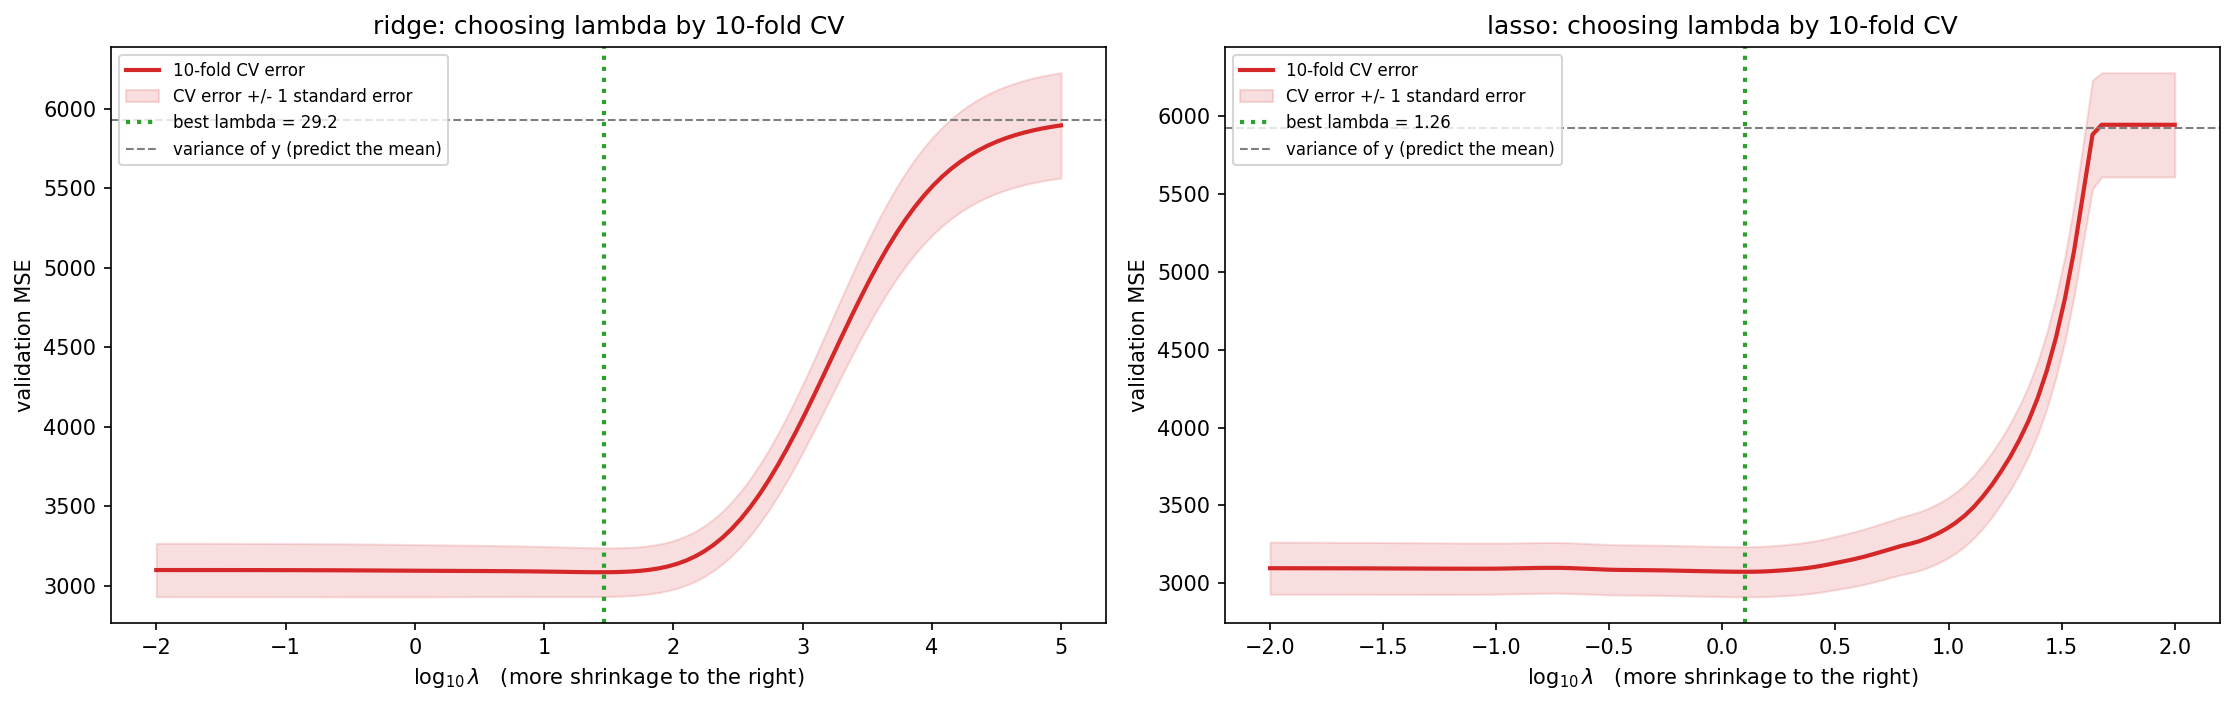


the lasso at lambda = 1.262, fitted on all development rows, keeps 7 of the 10 features


In [20]:
folds = list(KFold(n_splits=10, shuffle=True, random_state=0).split(X_dev_raw))   # ONE set of folds, used everywhere
K = len(folds)


def cv_errors(path_fn, X_raw, y, folds, lams):
    '''K-fold cross-validation of a whole path of lambdas.

    path_fn : ridge_path or lasso_path
    returns : array of shape (len(lams), K), the validation MSE of every lambda on every fold
    '''
    errors = np.empty((len(lams), len(folds)))
    for f, (tr, va) in enumerate(folds):
        Z_tr = standardise(X_raw[tr], X_raw[tr])         # scale with the TRAINING part of this fold only
        Z_va = standardise(X_raw[tr], X_raw[va])
        b0s, B = path_fn(Z_tr, y[tr], lams)
        for i in range(len(lams)):
            errors[i, f] = mse(y[va], predict(b0s[i], B[i], Z_va))
    return errors


ridge_cv = cv_errors(ridge_path, X_dev_raw, y_dev, folds, lams_ridge)
lasso_cv = cv_errors(lasso_path, X_dev_raw, y_dev, folds, lams_lasso)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
best = {}
for ax, name, lams, errors in [(axes[0], "ridge", lams_ridge, ridge_cv), (axes[1], "lasso", lams_lasso, lasso_cv)]:
    mean, se = errors.mean(axis=1), errors.std(axis=1) / np.sqrt(K)        # CV error and its standard error
    i_best = int(np.argmin(mean))
    best[name] = lams[i_best]
    ax.plot(np.log10(lams), mean, color="tab:red", lw=2, label="10-fold CV error")
    ax.fill_between(np.log10(lams), mean - se, mean + se, color="tab:red", alpha=0.15,
                    label="CV error +/- 1 standard error")
    ax.axvline(np.log10(lams[i_best]), color="tab:green", linestyle="dotted", lw=2,
               label=f"best lambda = {lams[i_best]:.3g}")
    ax.axhline(y_dev.var(), color="tab:grey", linestyle="dashed", lw=1, label="variance of y (predict the mean)")
    ax.set_xlabel(r"$\log_{10}\lambda$   (more shrinkage to the right)")
    ax.set_ylabel("validation MSE")
    ax.set_title(f"{name}: choosing lambda by 10-fold CV")
    ax.legend(fontsize=8, loc="upper left")
    print(f"{name}: best lambda = {lams[i_best]:.4f},  CV error = {mean[i_best]:.1f}  (standard error {se[i_best]:.1f}),"
          f"  CV error at the smallest lambda (almost OLS) = {mean[0]:.1f}")
plt.tight_layout()
plt.show()

lam_ridge, lam_lasso = best["ridge"], best["lasso"]
print(f"\nthe lasso at lambda = {lam_lasso:.3f}, fitted on all development rows, keeps "
      f"{np.sum(lasso_fit(Z_dev, y_dev, lam_lasso)[1] != 0)} of the {p} features")

**Line by line**

- `KFold(n_splits=10, shuffle=True, random_state=0).split(X_dev_raw)` : ten (training rows, validation rows) pairs.
  Our own `kfold_indices` of Practical 4 gives identical folds. `list(...)` stores them so they can be reused.
- `cv_errors(path_fn, ...)` : a function can be passed to another function like any other value. `path_fn` is either
  `ridge_path` or `lasso_path`, so one CV function serves both methods.
- `for f, (tr, va) in enumerate(folds)` : `enumerate` gives the fold number `f` together with the fold itself, which
  is unpacked into `tr` and `va`.
- `errors.mean(axis=1)` : the average over the 10 folds (the columns), one number per $\lambda$: the CV error.
- `errors.std(axis=1) / np.sqrt(K)` : the **standard error** of that average. The ten fold errors vary, and the
  average of $K$ numbers is $\sqrt{K}$ times less variable than one of them.
- `ax.fill_between(x, low, high)` : shades the band between two curves, as in Practical 4.
- `f"{lams[i_best]:.3g}"` : the `g` format shows 3 significant digits, whatever the size of the number.

**Reading the plots.** This is the U-shaped validation curve of Practical 4 again, now with $\lambda$ as the knob.

- **On the right** (very large $\lambda$) every coefficient is shrunk to almost zero, the model predicts roughly the
  mean for everyone, and the CV error climbs to the variance of $y$ (the grey line). That is **underfitting**.
- **On the left** (tiny $\lambda$) we are back at OLS, with a CV error of about 3097.
- **In between**, at $\lambda \approx 29$ for ridge and $\lambda \approx 1.26$ for the lasso, the CV error is lowest:
  about 3084 for ridge and 3074 for the lasso. The chosen lasso keeps 7 of the 10 features.

But look at the size of the improvement: from about 3097 to about 3074, while the standard error is about 155. The
bottom of the curve is very **flat**, and the gain over OLS is much smaller than the noise in the CV estimate. With
only 10 predictors and 353 rows, OLS is not badly overfitting this data, so shrinkage cannot improve the
*predictions* much. (Its real benefit here is the stability of the coefficients, which Part 7 measures.) When the
curve is this flat, the one-standard-error rule of Practical 4 would pick a much larger $\lambda$; that is Exercise 2.

### 6c. Checking the cross-validation against `GridSearchCV`

`GridSearchCV` runs the same procedure: for every value in a grid, cross-validate, and pick the best. We give it a
pipeline that standardises and then fits `Ridge` or `Lasso`, so that the standardisation happens inside every fold,
exactly as in our function, and we give it **our own folds**.

In [21]:
search_ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                            {"ridge__alpha": lams_ridge}, cv=folds, scoring="neg_mean_squared_error")
search_ridge.fit(X_dev_raw, y_dev)

search_lasso = GridSearchCV(make_pipeline(StandardScaler(), Lasso(tol=1e-10, max_iter=100000)),
                            {"lasso__alpha": lams_lasso}, cv=folds, scoring="neg_mean_squared_error")
search_lasso.fit(X_dev_raw, y_dev)

print("ridge: same CV error for all 100 lambdas:",
      np.allclose(ridge_cv.mean(axis=1), -search_ridge.cv_results_["mean_test_score"]))
print("ridge: same best lambda                 :", np.isclose(lam_ridge, search_ridge.best_params_["ridge__alpha"]))
print("lasso: same CV error for all 100 lambdas:",
      np.allclose(lasso_cv.mean(axis=1), -search_lasso.cv_results_["mean_test_score"]))
print("lasso: same best lambda                 :", np.isclose(lam_lasso, search_lasso.best_params_["lasso__alpha"]))
print(f"lasso: largest difference in CV error   : "
      f"{np.abs(lasso_cv.mean(axis=1) + search_lasso.cv_results_['mean_test_score']).max():.1e}")

ridge: same CV error for all 100 lambdas: True
ridge: same best lambda                 : True
lasso: same CV error for all 100 lambdas: True
lasso: same best lambda                 : True
lasso: largest difference in CV error   : 5.6e-07


**Line by line**

- `make_pipeline(StandardScaler(), Ridge())` : one model that first standardises and then fits ridge. Inside
  `GridSearchCV` the scaler is refitted on the training part of every fold, which is exactly what our `cv_errors`
  does.
- `{"ridge__alpha": lams_ridge}` : the **parameter grid**. `make_pipeline` names each step after its class in lower
  case (`"ridge"`, `"lasso"`), and `step__parameter` (two underscores) means "the parameter `alpha` of the step called
  `ridge`" (Practical 4, 7d).
- `cv=folds` : our own list of folds, so both methods use exactly the same rows.
- `cv_results_["mean_test_score"]` : the average validation score of every grid value. The score is $-\text{MSE}$,
  so we flip the sign before comparing.
- `best_params_` : the winning grid value.

**Reading the output.** All four checks print `True`. Our cross-validation gives the same 100 CV errors as the
library for both methods (for the lasso the largest difference is below $10^{-6}$, the tolerance of the two
iterative solvers), and both choose the same $\lambda$.

## Part 7: OLS, subset selection, ridge and lasso on correlated predictors

Every choice has now been made on the development rows: the subset by BIC (Part 3), the ridge $\lambda$ and the lasso
$\lambda$ by cross-validation (Part 6). We compare the methods in three ways:

1. **test error**: each final model is fitted on all development rows and evaluated **once** on the test set;
2. **coefficient stability**: how much the coefficients change when the data change a little;
3. **sparsity**: how many coefficients are exactly zero.

We use the test set here only to **compare** methods whose settings are already fixed, never to choose a $\lambda$
or a subset. We do this first on the 10 original features, then on a harder version with 55 correlated features.

### 7a. The final models and their test error (10 features)

In [22]:
bic_cols = bs_cols[best_d["BIC"]]                         # the subset chosen by BIC in Part 3
b0_sub, b_sub = ols_fit(Z_dev[:, bic_cols], y_dev)
b_sub_all = np.zeros(p)                                   # write it as a 10-vector, with 0 for the left-out features
b_sub_all[bic_cols] = b_sub

final10 = {"OLS": ols_fit(Z_dev, y_dev),
           "best subset (BIC)": (b0_sub, b_sub_all),
           "ridge": ridge_fit(Z_dev, y_dev, lam_ridge),
           "lasso": lasso_fit(Z_dev, y_dev, lam_lasso)}
setting10 = {"OLS": "all 10 features", "best subset (BIC)": f"d = {best_d['BIC']}",
             "ridge": f"lambda = {lam_ridge:.2f}", "lasso": f"lambda = {lam_lasso:.3f}"}

rows = []
for name, (b0, b) in final10.items():
    squared_errors = (y_test - predict(b0, b, Z_test)) ** 2          # the test set, used once per method
    rows.append({"method": name, "setting": setting10[name],
                 "training MSE": mse(y_dev, predict(b0, b, Z_dev)),
                 "test MSE": squared_errors.mean(),
                 "standard error of test MSE": squared_errors.std() / np.sqrt(len(y_test)),
                 "zero coefficients": int(np.sum(b == 0))})
results10 = pd.DataFrame(rows).set_index("method")

print(f"baseline: predicting the development mean for every test patient gives a test MSE of "
      f"{mse(y_test, y_dev.mean()):.1f}")
display(results10)
print("coefficients of the four final models:")
pd.DataFrame({name: b for name, (b0, b) in final10.items()}, index=feature_names)

baseline: predicting the development mean for every test patient gives a test MSE of 5945.2


,setting,training MSE,test MSE,standard error of test MSE,zero coefficients
method,,,,,
OLS,all 10 features,2900.9930,2739.0987,426.6329,0
best subset (BIC),d = 6,2916.8640,2755.6917,432.5314,4
ridge,lambda = 29.15,2927.5543,2734.1759,413.6633,0
lasso,lambda = 1.262,2931.2306,2708.8919,414.5967,3


coefficients of the four final models:


,OLS,best subset (BIC),ridge,lasso
age,-0.2628,0.0000,0.1387,0.0000
sex,-12.0293,-11.2908,-10.4297,-9.1424
bmi,24.1495,24.5614,23.0798,24.2029
bp,16.5122,16.4525,15.1260,14.4460
s1,-40.4625,-39.1251,-5.9224,-6.9388
s2,23.2797,26.4876,-4.1441,0.0000
s3,4.7473,0.0000,-10.0929,-11.2511
s4,8.7128,0.0000,5.6009,0.0000
s5,35.6484,38.3335,21.5262,24.5773
s6,2.7397,0.0000,3.6224,1.9970


**Line by line**

- `b_sub_all[bic_cols] = b_sub` : the subset model only has 6 coefficients. Writing them into a vector of 10 zeros
  puts each one at its feature's position, so all four models can be handled in the same way.
- `final10` : a dictionary from a method name to its `(b0, b)` pair. `for name, (b0, b) in final10.items()` unpacks
  each entry.
- `squared_errors.std() / np.sqrt(len(y_test))` : the test MSE is an average of 89 squared errors, so its standard
  error is their standard deviation divided by $\sqrt{89}$, the same idea as the standard error of a test error rate
  in Practical 4, 7e.
- `mse(y_test, y_dev.mean())` : predicting one number for everybody. NumPy broadcasting stretches the single number to
  all 89 test patients.

**Reading the output.**

- All four models are far better than the baseline (about 5945), and on the test set they are **almost equally good**:
  2739 for OLS, 2756 for best subset, 2734 for ridge and 2709 for the lasso. The differences (at most about 47) are
  tiny compared with the standard error of a test MSE from 89 patients (over 400). On 10 features the methods
  **predict** about equally well, just as the flat CV curves of 6b suggested.
- The **training** MSE tells the opposite story: OLS has the lowest (it is the best possible fit to the training rows),
  and the shrunk models have higher training errors. That is the point of shrinkage: give up a little training fit to
  gain stability.
- The **coefficients** are where the methods really differ. OLS and best subset both give `s1` about $-40$ and `s2`
  about $+23$ to $+26$. Ridge gives them $-5.9$ and $-4.1$: small, same sign, weight shared. The lasso gives `s1`
  $-6.9$ and sets `s2` to **exactly 0**, along with `age` and `s4`. The shrunk models tell a much simpler story about
  cholesterol, and predict just as well.

### 7b. Coefficient stability: the bootstrap

The development rows are one random sample of patients. If a different hospital had collected a different sample,
how different would the coefficients be? We cannot collect new patients, but we can **imitate** it with the
**bootstrap**: draw $n$ rows from the development set **with replacement** (so some patients appear twice and others
not at all), refit, and repeat many times. A stable method gives similar coefficients on every bootstrap sample;
an unstable one jumps around.

We draw 200 bootstrap samples and refit OLS, ridge and the lasso on each, keeping each $\lambda$ fixed at the value
chosen in 6b.

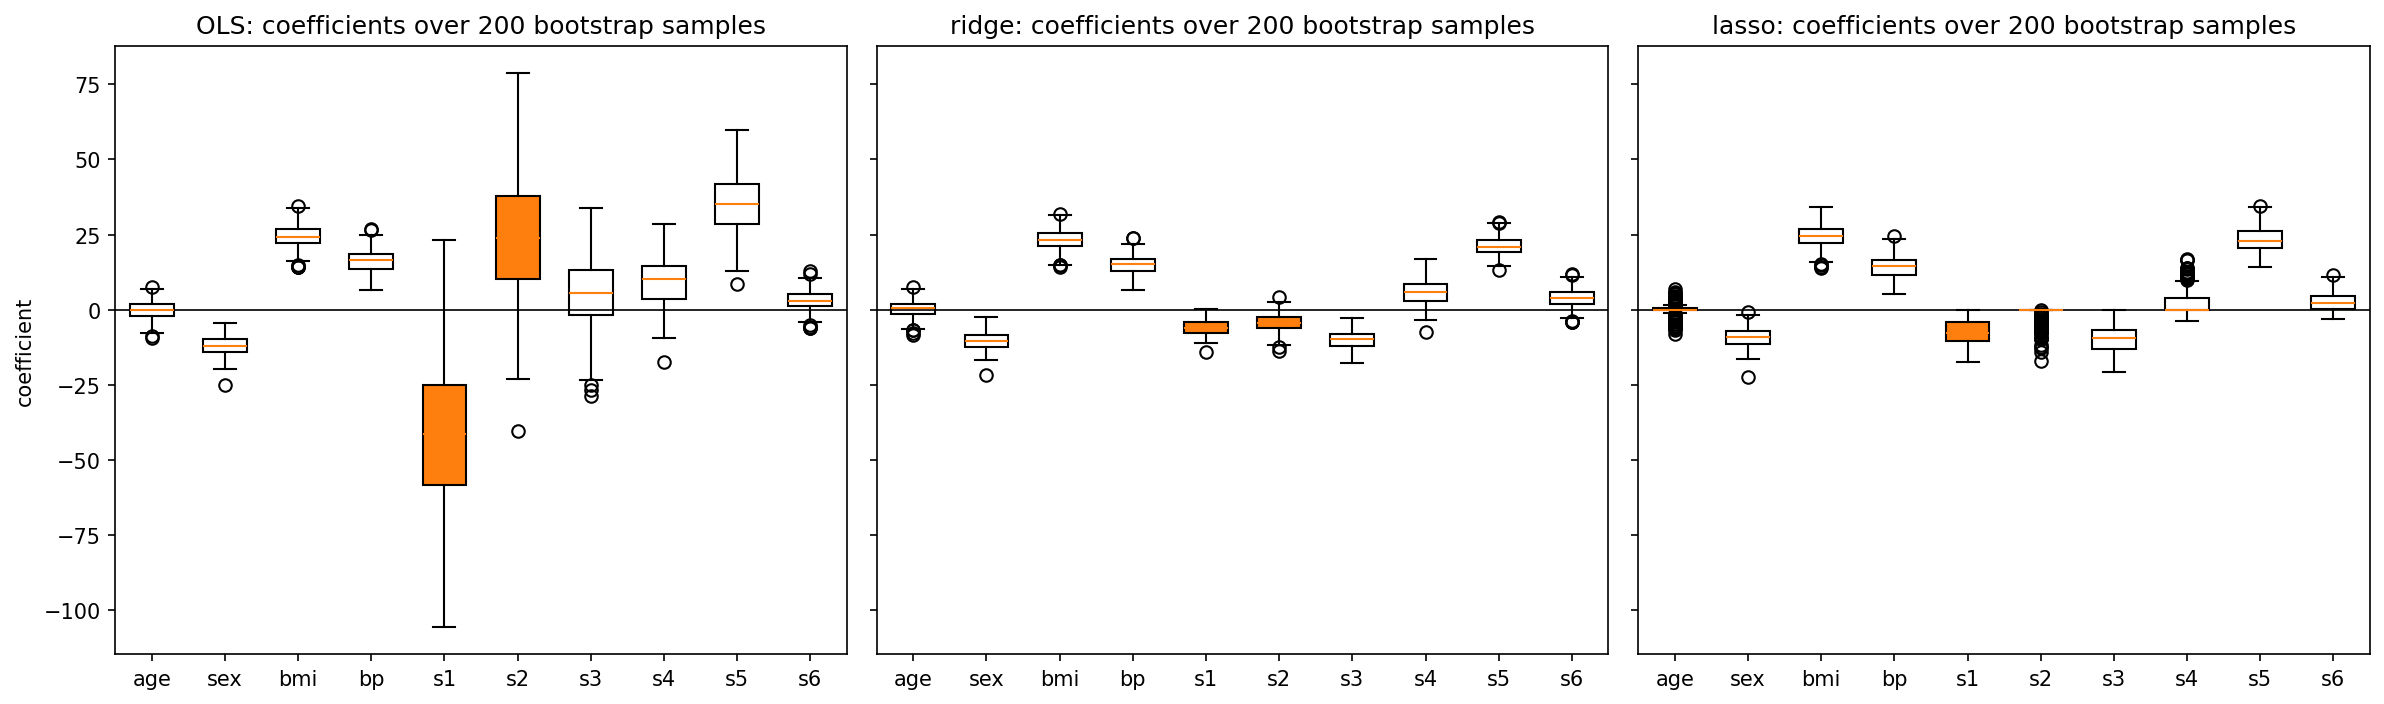

standard deviation of each coefficient over the bootstrap samples:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,average
OLS,3.2326,3.2925,3.7659,3.5705,23.1429,19.5429,11.8650,8.3342,9.4102,3.3284,8.9485
ridge,2.9147,2.9518,3.3464,3.0470,2.5218,2.9743,2.9961,4.1813,3.2574,2.9134,3.1104
lasso,2.1503,3.3368,3.8225,3.5055,4.4706,2.9950,4.4714,4.0301,4.2075,2.7329,3.5723


fraction of bootstrap samples in which the coefficient is positive:


,OLS,ridge,lasso
s1 > 0,0.045,0.005,0.0
s2 > 0,0.885,0.070,0.0


lasso: fraction of bootstrap samples in which each coefficient is exactly 0:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
lasso,0.41,0.0,0.0,0.0,0.135,0.8,0.025,0.555,0.0,0.215


In [23]:
N_BOOT = 200
rs = np.random.RandomState(0)                             # its own seeded generator, so the samples are reproducible
boot10 = {name: np.empty((N_BOOT, p)) for name in ["OLS", "ridge", "lasso"]}
for i in range(N_BOOT):
    idx = rs.randint(0, n_dev, size=n_dev)                # n_dev row numbers drawn WITH replacement
    Zb, yb = Z_dev[idx], y_dev[idx]
    boot10["OLS"][i] = ols_fit(Zb, yb)[1]
    boot10["ridge"][i] = ridge_fit(Zb, yb, lam_ridge)[1]
    boot10["lasso"][i] = lasso_fit(Zb, yb, lam_lasso)[1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (name, C) in zip(axes, boot10.items()):
    boxes = ax.boxplot(C, patch_artist=True, widths=0.6)["boxes"]
    for j, box in enumerate(boxes):
        box.set_facecolor("tab:orange" if feature_names[j] in ("s1", "s2") else "white")
    ax.set_xticks(range(1, p + 1))
    ax.set_xticklabels(feature_names)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{name}: coefficients over {N_BOOT} bootstrap samples")
axes[0].set_ylabel("coefficient")
plt.tight_layout()
plt.show()

spread = pd.DataFrame({name: C.std(axis=0) for name, C in boot10.items()}, index=feature_names)
spread.loc["average"] = spread.mean()
print("standard deviation of each coefficient over the bootstrap samples:")
display(spread.T)

print("fraction of bootstrap samples in which the coefficient is positive:")
display(pd.DataFrame({name: [np.mean(C[:, 4] > 0), np.mean(C[:, 5] > 0)] for name, C in boot10.items()},
                     index=["s1 > 0", "s2 > 0"]))

print("lasso: fraction of bootstrap samples in which each coefficient is exactly 0:")
pd.Series(np.mean(boot10["lasso"] == 0, axis=0), index=feature_names).to_frame("lasso").T

**Line by line**

- `rs.randint(0, n_dev, size=n_dev)` : 353 random whole numbers from 0 to 352. Some numbers come up twice or more,
  and on average about a third of the rows do not come up at all. Indexing with them gives one bootstrap sample.
- We do **not** re-standardise the bootstrap samples: every sample uses the same `Z_dev` scale, so the coefficients
  of different samples are measured in the same units and can be compared. Our `ridge_fit` and `lasso_fit` centre
  internally and divide by `col_sq`, so they stay correct even though a bootstrap sample's columns no longer have
  mean exactly 0 and standard deviation exactly 1.
- `ols_fit(Zb, yb)[1]` : `[1]` keeps only the coefficients and drops the intercept.
- `ax.boxplot(C, patch_artist=True)` : one box per column of `C`. The box covers the middle half of the 200 values,
  the line inside is the median, and the whiskers and dots show the spread beyond. `patch_artist=True` makes the
  boxes fillable, so we can colour the `s1` and `s2` boxes orange.
- `sharey=True` : all three panels use the **same vertical scale**, so the box sizes can be compared directly.
- `spread.loc["average"] = spread.mean()` : adds one more row with the column averages.

**Reading the plots and tables.** This is the clearest result of the practical.

- **OLS (left)**: the orange boxes are huge. Over the 200 samples the `s1` coefficient has a standard deviation of
  about 23 and `s2` about 19.5, against 3 to 4 for the features that are not strongly correlated (`age`, `sex`,
  `bmi`, `bp`). The **sign** of `s2` is positive in 88.5% of the samples and negative in the rest, and even `s1` is
  positive in 4.5% of them. A slightly
  different sample of patients would tell a completely different story about cholesterol.
- **Ridge (middle)**: the same two coefficients have standard deviations of only about 2.5 and 3. Averaged over all
  ten features, the ridge coefficients vary about **three times less** than the OLS ones (3.1 against 8.9).
- **Lasso (right)**: also stable (average 3.6). The last table shows *how* it achieves this: `s2` is exactly zero in
  80% of the samples, `s4` in about 55%, `age` in 41%. Faced with a correlated group, the lasso keeps one member and drops
  the others. Which one it drops can change from sample to sample, but `sex`, `bmi`, `bp` and `s5` are **never**
  dropped: the lasso is consistent about the features that really matter.

### 7c. A harder problem: 55 correlated predictors

In real projects one often adds **interaction** features: products of pairs of features, such as `bmi` $\times$ `bp`,
which let the effect of one feature depend on another. `PolynomialFeatures(degree=2, interaction_only=True)` adds all
$\binom{10}{2} = 45$ products to the 10 original features, giving 55 predictors. Products of correlated features are
themselves correlated, with each other and with the originals, so this is exactly the situation the practical is
about, with far more predictors for only 353 rows.

The new columns are computed **row by row** from each patient's own values, so no information passes between rows,
and we can build them separately for the development and the test rows. The test rows are the same 89 patients as
before.

In [24]:
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X55_dev_raw = poly.fit_transform(X_dev_raw)              # (353, 55): the 10 features and the 45 products
X55_test_raw = poly.transform(X_test_raw)                # (89, 55): the same columns for the test patients
names55 = poly.get_feature_names_out(feature_names)

Z55_dev = standardise(X55_dev_raw, X55_dev_raw)
Z55_test = standardise(X55_dev_raw, X55_test_raw)
p55 = Z55_dev.shape[1]

print("development:", X55_dev_raw.shape, "   test:", X55_test_raw.shape)
print("first 13 columns:", list(names55[:13]))
print("last 3 columns  :", list(names55[-3:]))

corr55 = np.corrcoef(Z55_dev, rowvar=False)
strength = np.abs(corr55[np.triu_indices(p55, k=1)])    # every pair once
print(f"\n{len(strength)} pairs of predictors: {np.sum(strength > 0.5)} with |correlation| > 0.5, "
      f"{np.sum(strength > 0.7)} with |correlation| > 0.7, largest {strength.max():.3f}")
print(f"best subset would need 2^{p55} = {2 ** p55:,} fits")

development: (353, 55)    test: (89, 55)
first 13 columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'age sex', 'age bmi', 'age bp']
last 3 columns  : ['s4 s5', 's4 s6', 's5 s6']

1485 pairs of predictors: 60 with |correlation| > 0.5, 18 with |correlation| > 0.7, largest 0.920
best subset would need 2^55 = 36,028,797,018,963,968 fits


**Line by line**

- `PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)` : `degree=2` means products of at most two
  features; `interaction_only=True` leaves out the squares ($x_j^2$) and keeps only products of two *different*
  features; `include_bias=False` leaves out a column of ones, because our functions add the intercept themselves.
- `fit_transform` on the development rows, then `transform` on the test rows. For this transformer `fit` only learns
  how many columns there are; nothing about the data is stored, so there is no leakage either way.
- `get_feature_names_out(feature_names)` : readable names for the new columns, such as `"bmi bp"` for the product
  of `bmi` and `bp`.
- We standardise the 55 columns with the development statistics, exactly as in 1b.
- `np.triu_indices(p55, k=1)` : the row and column positions of the entries **above** the diagonal, so every pair
  of predictors is counted once.

**Reading the output.** We now have 55 predictors for 353 patients. Of the 1485 pairs, 60 have a correlation above
0.5 in size and 18 above 0.7, the largest being 0.92. Best subset is out of the question ($2^{55}$ fits), which is
why shrinkage (or a stepwise method, Exercise 5) is needed here.

In [25]:
# choose lambda by 10-fold CV on the development rows, with the SAME folds as before
# (our own functions were checked in Part 6, so here we let GridSearchCV do the work)
search55_ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                              {"ridge__alpha": lams_ridge}, cv=folds, scoring="neg_mean_squared_error")
search55_ridge.fit(X55_dev_raw, y_dev)
search55_lasso = GridSearchCV(make_pipeline(StandardScaler(), Lasso(max_iter=100000)),
                              {"lasso__alpha": lams_lasso}, cv=folds, scoring="neg_mean_squared_error")
search55_lasso.fit(X55_dev_raw, y_dev)
lam55_ridge = search55_ridge.best_params_["ridge__alpha"]
lam55_lasso = search55_lasso.best_params_["lasso__alpha"]
ols55_cv = cv_errors(ridge_path, X55_dev_raw, y_dev, folds, np.array([0.0])).mean()   # ridge with lambda = 0 is OLS

final55 = {"OLS": ols_fit(Z55_dev, y_dev),
           "ridge": ridge_fit(Z55_dev, y_dev, lam55_ridge),
           "lasso": lasso_fit(Z55_dev, y_dev, lam55_lasso)}
cv55 = {"OLS": ols55_cv, "ridge": -search55_ridge.best_score_, "lasso": -search55_lasso.best_score_}
setting55 = {"OLS": "all 55 features", "ridge": f"lambda = {lam55_ridge:.2f}", "lasso": f"lambda = {lam55_lasso:.3f}"}

rows = []
for name, (b0, b) in final55.items():
    squared_errors = (y_test - predict(b0, b, Z55_test)) ** 2       # the test set, used once per method
    rows.append({"method": name, "setting": setting55[name],
                 "CV MSE": cv55[name],
                 "training MSE": mse(y_dev, predict(b0, b, Z55_dev)),
                 "test MSE": squared_errors.mean(),
                 "standard error of test MSE": squared_errors.std() / np.sqrt(len(y_test)),
                 "zero coefficients": int(np.sum(b == 0)),
                 "largest |coefficient|": np.abs(b).max()})
results55 = pd.DataFrame(rows).set_index("method")
display(results55)

print("the", p55 - results55.loc["lasso", "zero coefficients"], "features kept by the lasso:")
print(list(names55[final55["lasso"][1] != 0]))

,setting,CV MSE,training MSE,test MSE,standard error of test MSE,zero coefficients,largest |coefficient|
method,,,,,,,
OLS,all 55 features,3596.5075,2373.1094,3470.3268,505.9114,0,471.8808
ridge,lambda = 77.43,3182.3097,2563.3139,3020.0404,431.0983,0,19.2668
lasso,lambda = 2.205,3074.4964,2690.3905,2764.8578,397.2717,35,23.1078


the 20 features kept by the lasso:
['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6', 'age sex', 'age bp', 'age s6', 'sex bp', 'sex s3', 'bmi bp', 'bmi s1', 'bmi s3', 'bmi s6', 'bp s3', 's1 s4', 's4 s5', 's4 s6']


**Line by line**

- The two `GridSearchCV` calls are those of 6c, now on the 55 columns and with the same folds and grids. The steps
  sheet allows the library here because our own cross-validation has already been checked against it.
- `Lasso(max_iter=100000)` : with 55 correlated columns coordinate descent needs more sweeps, so we raise the limit.
- `cv_errors(ridge_path, ..., np.array([0.0]))` : a neat reuse. Ridge with $\lambda = 0$ is OLS, so a "path" with the
  single value 0 gives the 10-fold CV error of OLS on the same folds.
- `best_score_` : the best mean validation score, which is $-\text{MSE}$, so we flip its sign.
- The final models are fitted with **our own** functions on all development rows, and each is evaluated once on the
  test rows.

**Reading the output.** With 55 predictors the picture changes completely.

- **OLS overfits.** It has the lowest training MSE (about 2373, much lower than with 10 features) but the **worst**
  test MSE (about 3470) and the worst CV error (about 3597). The gap between training and test error is the
  overfitting signature of Practical 4. Its largest coefficient is about **472** in size, against about 40 with
  10 features. The worst offenders are the cholesterol columns of 2b again: many of the new product columns contain
  them too, so they are now even more tangled.
- **Ridge** keeps all 55 features but shrinks them (largest coefficient about 19). Its test MSE is about 3020.
- **The lasso is clearly the best**: test MSE about 2765, the lowest of the three, using only **20 of the 55**
  features and setting the other **35 to exactly zero**. The kept features include the important main effects
  (`sex`, `bmi`, `bp`, `s1`, `s3`, `s5`, `s6`) and a handful of interactions.
- Compare with 10 features: the lasso's test MSE with 55 features (about 2765) is close to its 10-feature value
  (about 2709), while OLS got much worse (from 2739 to 3470). Shrinkage protects the model when we add many
  correlated predictors; plain least squares does not.

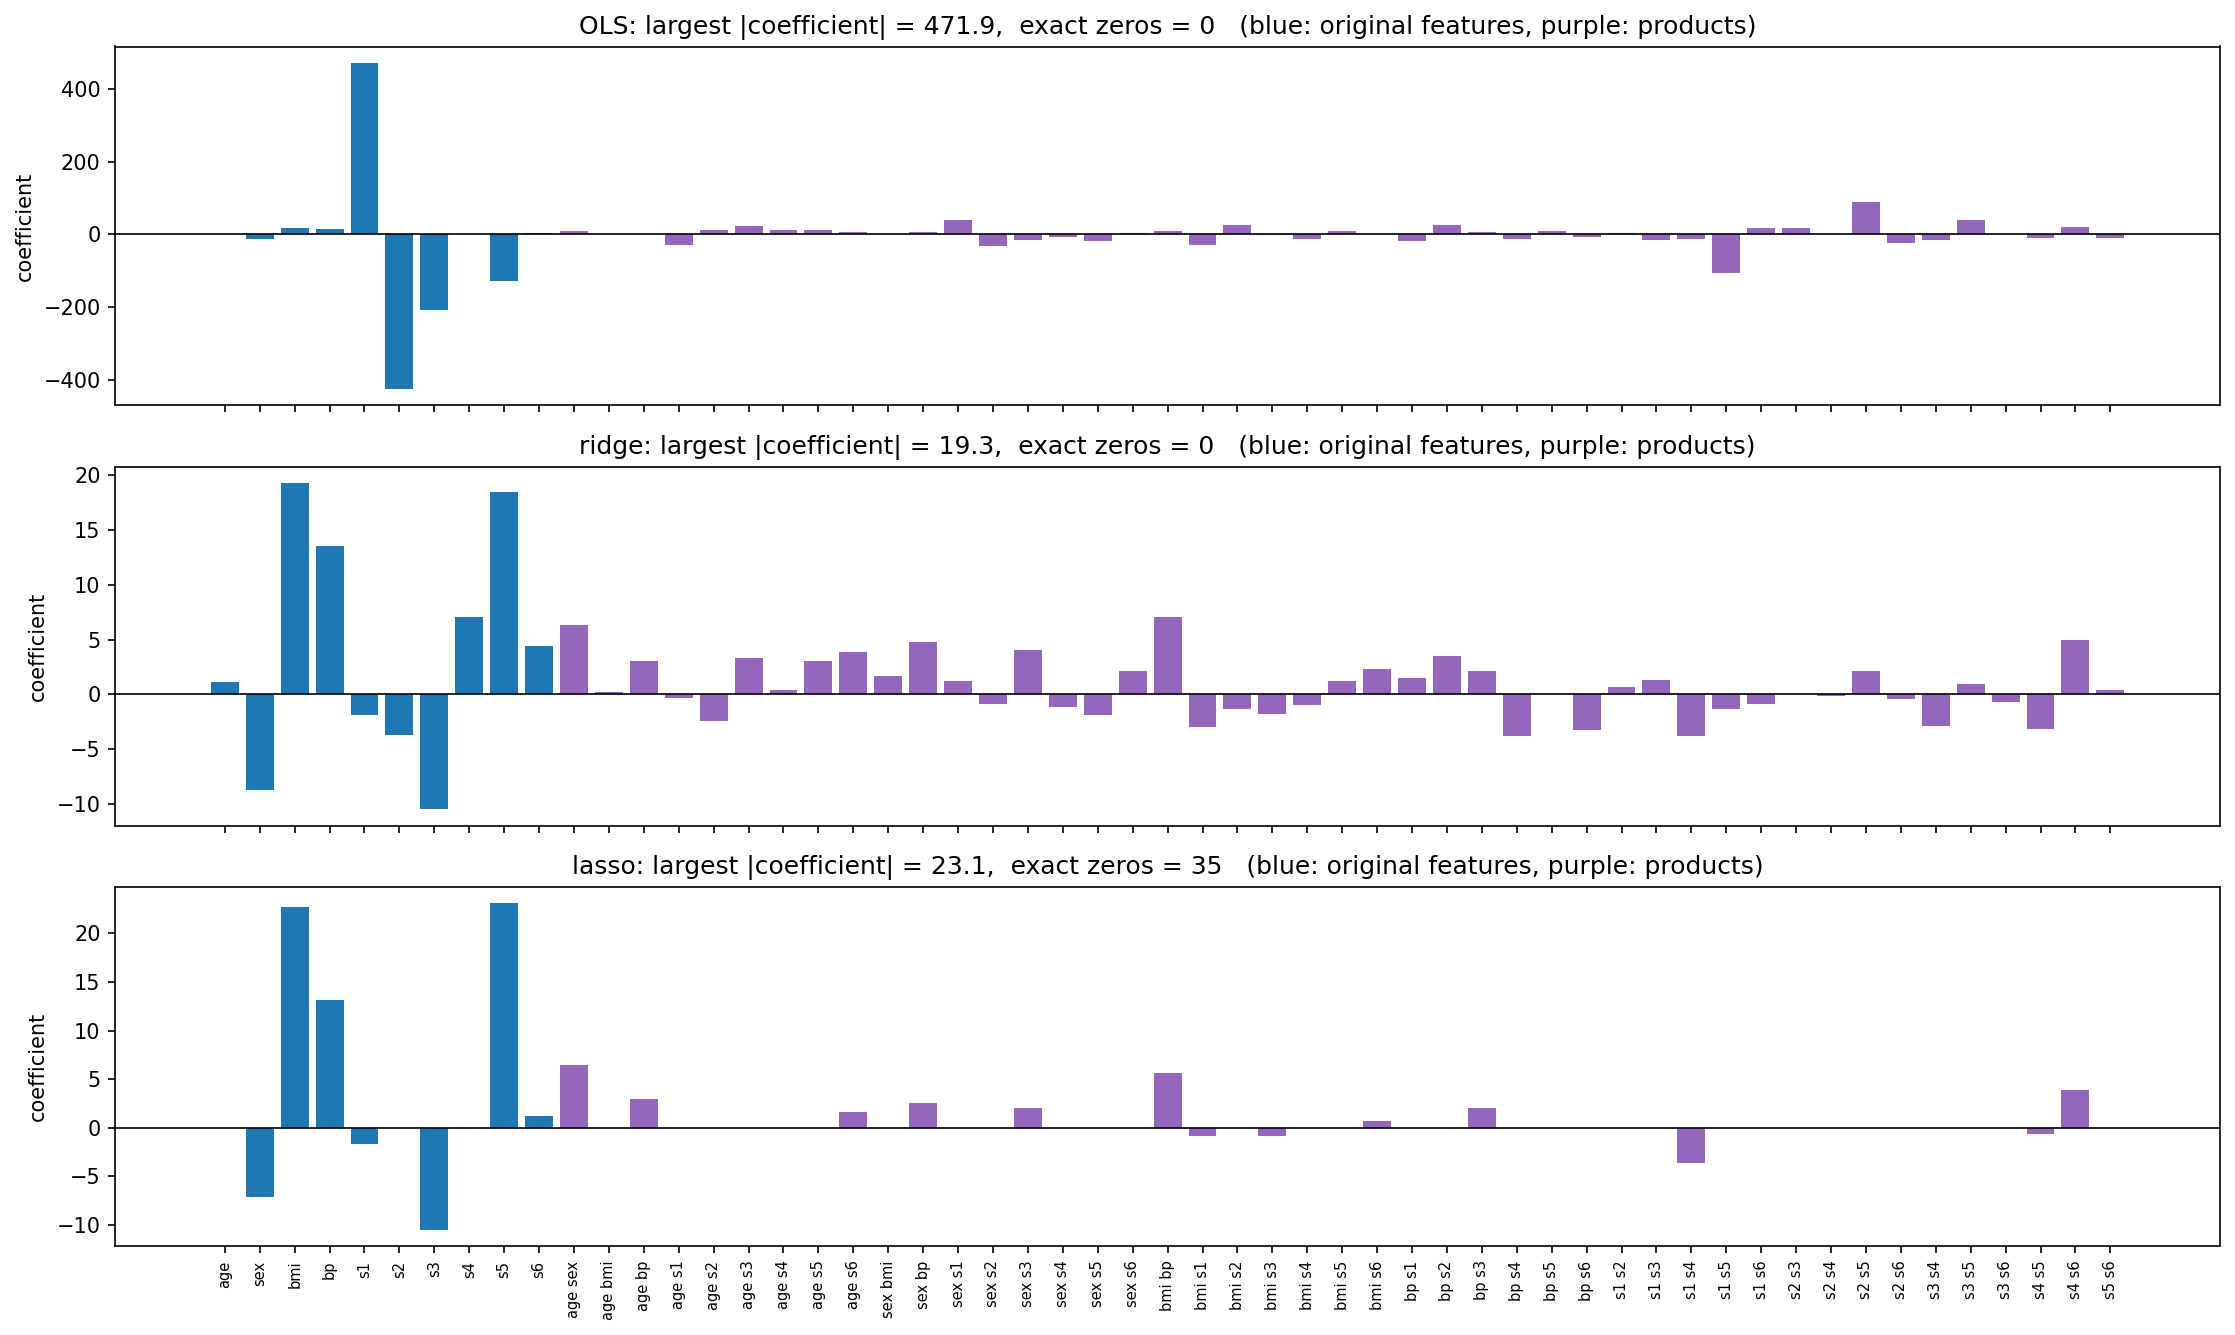

,average std of a coefficient over the bootstrap samples,average fraction of exact zeros
OLS,44.1959,0.0000
ridge,2.1106,0.0000
lasso,1.7782,0.5884


In [26]:
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
positions = np.arange(p55)
for ax, (name, (b0, b)) in zip(axes, final55.items()):
    ax.bar(positions, b, color=["tab:blue" if j < p else "tab:purple" for j in range(p55)])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("coefficient")
    ax.set_title(f"{name}: largest |coefficient| = {np.abs(b).max():.1f},  exact zeros = {np.sum(b == 0)}"
                 "   (blue: original features, purple: products)")
axes[-1].set_xticks(positions)
axes[-1].set_xticklabels(names55, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

rs = np.random.RandomState(0)
boot55 = {name: np.empty((N_BOOT, p55)) for name in ["OLS", "ridge", "lasso"]}
for i in range(N_BOOT):
    idx = rs.randint(0, n_dev, size=n_dev)
    Zb, yb = Z55_dev[idx], y_dev[idx]
    boot55["OLS"][i] = ols_fit(Zb, yb)[1]
    boot55["ridge"][i] = ridge_fit(Zb, yb, lam55_ridge)[1]
    boot55["lasso"][i] = lasso_fit(Zb, yb, lam55_lasso)[1]

pd.DataFrame({"average std of a coefficient over the bootstrap samples": [C.std(axis=0).mean() for C in boot55.values()],
              "average fraction of exact zeros": [np.mean(C == 0) for C in boot55.values()]},
             index=list(boot55.keys()))

**Line by line**

- `plt.subplots(3, 1, sharex=True)` : three panels stacked vertically, sharing the horizontal axis, so the same
  feature is in the same position on all three. Each panel has its **own** vertical scale; the titles give the
  largest coefficient so you can compare the scales.
- `color=[...]` : one colour per bar, blue for the 10 original features and purple for the 45 products.
- `rotation=90, fontsize=7` : 55 labels only fit if they are written vertically and small.
- The bootstrap loop is the one of 7b, now on the 55 columns.

**Reading the plot and the table.**

- **OLS (top)**: enormous coefficients. `s1` gets about $+472$ and `s2` about $-425$, with `s3` and `s5` also
  large and negative, and many products swinging up and down. Compare with the 10-feature OLS model, where `s1` was
  $-40$ and `s2` was $+23$: adding columns has not just made the two coefficients bigger, it has **swapped their
  signs**. Correlated columns are cancelling each other out, just as in 2b, only much worse.
- **Ridge (middle)**: every one of the 55 coefficients is present, but all are moderate in size.
- **Lasso (bottom)**: most bars are exactly zero; only 20 remain. A model with 20 coefficients is far easier to
  read and explain than one with 55.
- **Stability**: over 200 bootstrap samples an OLS coefficient varies, on average, with a standard deviation of about
  44; ridge about 2.1 and the lasso about 1.8, more than **twenty times** less. The lasso sets about 59% of the
  coefficients to exactly zero in a typical bootstrap sample.

### 7d. The final comparison

In [27]:
rows = []
for data, results, boot in [("10 features", results10, boot10), ("55 features", results55, boot55)]:
    for name in results.index:
        rows.append({"data": data, "method": name,
                     "setting": results.loc[name, "setting"],
                     "test MSE": results.loc[name, "test MSE"],
                     "zero coefficients": results.loc[name, "zero coefficients"],
                     "bootstrap std of coefficients": boot[name].std(axis=0).mean() if name in boot else np.nan})
final_table = pd.DataFrame(rows).set_index(["data", "method"])
final_table

setting   test MSE  zero coefficients  bootstrap std of coefficients
data        method                                                                                         
10 features OLS                all 10 features  2739.0987                  0                         8.9485
            best subset (BIC)            d = 6  2755.6917                  4                            NaN
            ridge               lambda = 29.15  2734.1759                  0                         3.1104
            lasso               lambda = 1.262  2708.8919                  3                         3.5723
55 features OLS                all 55 features  3470.3268                  0                        44.1959
            ridge               lambda = 77.43  3020.0404                  0                         2.1106
            lasso               lambda = 2.205  2764.8578                 35                         1.7782

**Line by line**

- The loop collects the rows of 7a and 7c into one table. `name in boot` is `False` for the best-subset model (it was
  not bootstrapped), so it gets `NaN` in the last column.
- `.set_index(["data", "method"])` : a **two-level** row label, so the table is grouped by dataset.

**Reading the table: the answer to the aim of this practical.**

| | OLS | ridge | lasso |
|-|-|-|-|
| **test error** | fine with 10 features, clearly worst with 55 (overfits) | as good as OLS with 10, better with 55 | as good as OLS with 10, clearly best with 55 |
| **coefficient stability** | unstable: correlated coefficients are large, with signs that flip between samples | stable: shares the weight between correlated predictors | stable: keeps one of a correlated group and drops the others |
| **coefficients driven to zero** | none | none, ever | 3 of 10, and 35 of 55 |

The main lessons:

1. With a **few** predictors and enough rows, all methods predict about equally well. Shrinkage still pays off,
   because it makes the coefficients **stable and interpretable**.
2. With **many correlated** predictors, OLS overfits and its coefficients become meaningless. Shrinkage then improves
   the **predictions** too.
3. **Ridge** is the safe choice when you believe most predictors matter a little. The **lasso** is the choice when
   you believe only a few matter, or when you want a short, readable model.
4. **Subset selection** gives a readable model too, but it is all-or-nothing, it keeps correlated pairs with wild
   OLS coefficients, and best subset becomes impossible beyond about 30 predictors.

## Summary

| procedure | what it does | our code | checked against | result of the check |
|-|-|-|-|-|
| standardisation | mean 0, standard deviation 1, using the development rows only | `standardise` | `StandardScaler` | identical |
| OLS | solve the normal equations $A^{\top}A\,w = A^{\top}y$ | `ols_fit` | `LinearRegression` | identical coefficients |
| model-selection criteria | training fit plus a penalty for size: AIC, BIC, $C_p$, adjusted $R^2$ | `criteria` | `statsmodels` OLS | identical (AIC and BIC up to a constant) |
| best subset | every subset; smallest RSS for each size | `best_subset` | no library version: 1024 fits, RSS never rises, $M_{10}$ = OLS | all `True` |
| forward and backward stepwise | greedily add or remove one predictor at a time | `forward_stepwise`, `backward_stepwise` | `SequentialFeatureSelector` | identical selections |
| ridge | closed form $(X^{\top}X + \lambda I)^{-1}X^{\top}y$ | `ridge_fit` | `Ridge` | identical |
| lasso | coordinate descent with soft thresholding | `lasso_fit` | `Lasso` | identical to $10^{-6}$ |
| shrinkage paths | coefficients against $\lambda$ | `ridge_path`, `lasso_path` | built from the checked fits | ridge: no zeros; lasso: zeros one by one |
| choosing $\lambda$ | 10-fold CV, standardising inside each fold | `cv_errors` | `GridSearchCV` | identical CV errors, same $\lambda$ |
| final comparison | test MSE once, bootstrap stability, exact zeros | Part 7 | | lasso best with 55 features |

**The one sentence version:** when predictors are correlated, least squares cannot decide how to share the credit
between them and gives large, unstable coefficients; subset selection removes predictors (chosen by AIC, BIC, $C_p$
or adjusted $R^2$, by trying every subset or by greedy steps), ridge shrinks all coefficients smoothly and shares the
weight, and the lasso shrinks and sets some coefficients to exactly zero, with the amount of shrinkage chosen by
cross-validation on the development rows and the test set used only at the very end.

**How this connects to the previous practicals.** Practical 1 fitted linear regression by least squares; here the
same normal equations get a $\lambda I$ added (ridge) or are replaced by coordinate descent (lasso). Practical 2
introduced correlation; here we saw what strong correlation does to least squares. Practical 3 explained the
bias and variance trade-off: shrinkage accepts a little bias (higher training error) in exchange for much lower
variance (stable coefficients), which is exactly what the bootstrap showed. Practical 4 taught us to lock away the test
set, to choose hyper-parameters by cross-validation and to standardise inside each fold; $\lambda$ was chosen in
exactly that way, and the U-shaped validation curve reappeared with $\lambda$ as the knob.

# Exercises

Five exercises, roughly in order of difficulty. Write your code in the empty cell below each one. Everything you need
is already defined or imported above, except where an exercise tells you to import one extra item.

**Before you start, a habit worth keeping.** Whenever you see a coefficient, ask: *would it look the same on a
slightly different sample?* And whenever you see an error, ask, as in Practical 4: *which rows was it computed on,
and were those rows used to choose anything?*

## Exercise 1: Perfectly correlated predictors

What happens in the most extreme case, when one predictor is an **exact copy** of another?

1. Build `Z_dup = np.column_stack([Z_dev, Z_dev[:, 4]])`: the development features plus an 11th column that is an
   exact copy of `s1`.
2. Try `ols_fit(Z_dup, y_dev)`. Do you get an error, or numbers that make no sense? Explain why, using the rank of
   $A^{\top}A$. Then try `LinearRegression().fit(Z_dup, y_dev)`: it does return an answer. How do the two `s1`
   coefficients compare?
3. Fit `ridge_fit(Z_dup, y_dev, 10)`. Compare the two copies' coefficients with each other, and with the `s1`
   coefficient of `ridge_fit(Z_dev, y_dev, 10)`. What does ridge do with two identical columns?
4. Fit `lasso_fit(Z_dup, y_dev, 1.0)`. How is the weight split between the two copies? Now move the copy to the
   **front** (`np.column_stack([Z_dev[:, 4], Z_dev])`) and fit again. What changes? (Hint: when two columns are identical,
   is there only one best way to split the weight between them under the lasso penalty?) What does this tell you
   about interpreting which of two correlated features the lasso keeps?

In [28]:
# Your code for Exercise 1

## Exercise 2: The one-standard-error rule for $\lambda$

In 6b the CV curves were very flat near their minimum, and the gain over OLS was smaller than one standard error.

1. For ridge and for the lasso, find the **largest** $\lambda$ whose CV error is at most *(best CV error + its
   standard error)*. Use `ridge_cv`, `lasso_cv`, `lams_ridge` and `lams_lasso`.
2. Redraw the two CV plots of 6b with this second $\lambda$ marked.
3. How many features does the lasso keep at the one-standard-error $\lambda$? Which ones?
4. Repeat the bootstrap of 7b for the lasso at this $\lambda$. Is it more or less stable than at the CV-best $\lambda$?
   Why might a simpler model be preferable when the CV errors cannot be told apart?

In [29]:
# Your code for Exercise 2

## Exercise 3: Choosing the subset size by cross-validation

In Part 3 the four criteria chose the size $d$ without a validation set. Choose it by 10-fold cross-validation
instead.

1. For each of the 10 `folds`: standardise with the fold's training part, run `best_subset` on the **training part
   only**, and for every size $d$ compute the validation MSE of that fold's $M_d$ on the validation part.
2. Average over the folds to get a CV error for every $d$, and plot it with $\pm 1$ standard error. Which $d$ does
   cross-validation choose? Compare with the choices of AIC, BIC, $C_p$ and adjusted $R^2$ in 3c.
3. Why must `best_subset` be run again **inside every fold**, instead of using the models $M_d$ found on all the
   development rows? (Hint: Practical 4, Exercise 4, on leakage.)
4. Do the different folds choose the same features for $M_6$? Count how often each feature appears in $M_6$ over the
   10 folds.

In [30]:
# Your code for Exercise 3

## Exercise 4: The elastic net

The **elastic net** mixes the two penalties. In scikit-learn's scaling it minimises

$$\frac{1}{2n}\,\text{RSS} + \lambda\,\alpha \sum_j \lvert\beta_j\rvert + \frac{\lambda\,(1-\alpha)}{2} \sum_j \beta_j^2,$$

where $\alpha$ (`l1_ratio`) is between 0 and 1. In coordinate descent the only change is the update:
$\beta_j \leftarrow S(\rho_j,\, \lambda\alpha) \,/\, \big(\tfrac1n x_j^{\top}x_j + \lambda(1-\alpha)\big)$.

1. Copy `lasso_fit` into `elastic_net_fit(Z, y, lam, l1_ratio)` and change that one line. Check it against
   `ElasticNet(alpha=lam, l1_ratio=l1_ratio, tol=1e-10, max_iter=100000)` (import it from `sklearn.linear_model`)
   for several values of `lam` and `l1_ratio`.
2. Check that `l1_ratio=1` gives exactly `lasso_fit`, and that `l1_ratio=0` gives `ridge_fit` with a ridge $\lambda$
   of $n\lambda$. Explain the factor $n$ by comparing the two objectives.
3. Repeat part 4 of Exercise 1 with `l1_ratio=0.5`. How is the weight now split between the two copies of `s1`? Why
   is the elastic net often preferred to the lasso when predictors come in correlated groups?

In [31]:
# Your code for Exercise 4

## Exercise 5: Forward stepwise on the 55 features

Best subset is impossible with 55 predictors, but forward stepwise is not.

1. Run `forward_stepwise(Z55_dev, y_dev)`. How many models does it fit? How long does it take (use `import time` and
   `time.perf_counter()`)?
2. For every size compute BIC with `criteria`. **Careful:** its default values belong to the 10-feature model, so pass
   `n`, `tss` and `sigma2` explicitly, with `sigma2` estimated from the full 55-feature OLS model. Which size does BIC
   choose, and which features?
3. Compare the BIC-chosen features with the 20 features kept by the lasso in 7c. How many do they share?
4. Fit OLS on the BIC-chosen subset of the development rows and compute its test MSE. Add it as a fourth row to the
   55-feature results of 7c. How does greedy subset selection compare with the lasso here, in test error and in the
   size of its coefficients?

In [32]:
# Your code for Exercise 5